# 02 – Futuros y cobertura
**Lab #2 – Derivados Financieros** · Puntos 6 a 12 (derivados/cobertura)

> Versión 2 (asesoría del 09/11/2026): CSCO, ADI y AMGN · portafolio GMV · todo mensual · 33 contratos cortos NQ · simulación con μ = r_f + ERP · insumos leídos de los archivos `_v2` que deja `01_portafolio`. Los Puntos 6 a 12 ya están en v2.

## Configuración

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RAIZ = Path("..").resolve()              # raíz del repo (el notebook corre desde notebooks/)
if str(RAIZ) not in sys.path:
    sys.path.append(str(RAIZ))           # para poder importar src/futuros.py

from src.futuros import NQ               # especificaciones del NQ (fuente: CME Group)

PROC = RAIZ / "data" / "processed"
ACCIONES = ["CSCO", "ADI", "AMGN"]

# Insumos v2 que deja 01_portafolio (nada escrito a mano)
ret_m  = pd.read_csv(PROC / "retornos_mensuales_v2.csv", index_col=0, parse_dates=True)  # 120 retornos log mensuales
cov_m  = pd.read_csv(PROC / "cov_mensual_v2.csv", index_col=0)                           # Σ mensual
port   = pd.read_csv(PROC / "portafolios_markowitz_v2.csv", index_col=0)["GMV (definitivo)"]
betas  = pd.read_csv(PROC / "betas_capm_v2.csv", index_col=0)                            # betas mensuales (P5)
var_m  = pd.read_csv(PROC / "var_mensual_v2.csv", index_col=0)                           # VaR mensual (P4)
var_cs = pd.read_csv(PROC / "var_cubierto_vs_sin_v2.csv", index_col=0)                   # VaR cubierto vs. sin (P4)

w      = port[[f"Peso {a}" for a in ACCIONES]].to_numpy()       # pesos del GMV
montos = port[[f"Monto {a} (USD)" for a in ACCIONES]]           # USD por acción
V0     = 35_000_000                                             # capital del enunciado (USD)
assert abs(montos.sum() - V0) < 1, "los montos del GMV no suman V0"
assert abs(w.sum() - 1) < 1e-9 and (w > 0).all()                # regla de pesos v2

beta_p = betas.loc["Portafolio GMV", "β"]                       # β mensual del portafolio (P5)
print("Pesos GMV:", {a: round(float(x), 4) for a, x in zip(ACCIONES, w)})
print(f"β del portafolio (mensual) = {beta_p:.4f}")


Pesos GMV: {'CSCO': 0.3671, 'ADI': 0.1937, 'AMGN': 0.4392}
β del portafolio (mensual) = 0.5401


## Punto 6 – Número óptimo de contratos (R8 – 7 %)

La idea es saber cuántos futuros del Nasdaq-100 hay que vender para que el portafolio quede "neutro" frente al mercado. No basta con dividir los USD 35 M entre lo que vale un contrato, porque el portafolio no se mueve uno a uno con el índice: se mueve $\beta_p$ veces. Por eso lo que se cubre es la exposición sistemática $\beta_p \cdot V_p$.

$$N^* = \frac{\beta_p \cdot V_p}{F_0 \cdot Q_F}$$

| Insumo | De dónde sale |
|---|---|
| $\beta_p$ | β mensual del GMV, Punto 5 (`betas_capm_v2.csv`) |
| $V_p$ | USD 35.000.000 (enunciado; se verifica que los montos del GMV sumen eso) |
| $F_0$ | settle del NQZ6 al 30/10/2026 (CME Group, Settlements) |
| $Q_F$ | USD 20 por punto del índice (CME Group, Contract Specs; detalle en el Punto 7) |

Usamos la β mensual porque todo el lab va en mensual (VaR, betas, simulación y liquidación de la cuenta de margen). Así no mezclamos unidades.

In [2]:
# Punto 6: número óptimo de contratos
Vp = V0                                           # valor del portafolio al 30/10/2026 (USD)
F0 = NQ["F0"]                                     # settle del NQZ6 al 30/10/2026
expo_contrato = F0 * NQ["Q_F"]                    # USD que mueve un contrato: F0 × Q_F
expo_sist = beta_p * Vp                           # exposición sistemática a cubrir: βp × Vp

N_star = expo_sist / expo_contrato                # N* sin redondear
N_abajo, N_arriba = int(np.floor(N_star)), int(np.ceil(N_star))

# Las dos opciones de redondeo, lado a lado
opciones = pd.DataFrame({
    "Contratos": [N_abajo, N_arriba],
    "Exposición cubierta (USD)": [N_abajo * expo_contrato, N_arriba * expo_contrato],
})
opciones["Razón de cobertura"] = opciones["Contratos"] / N_star
opciones["Exposición que queda (USD)"] = expo_sist - opciones["Exposición cubierta (USD)"]   # + sin cubrir, − sobrecubierta
opciones.index = ["Hacia abajo", "Hacia arriba"]

print(f"Exposición por contrato = {expo_contrato:,.2f} USD")
print(f"βp × Vp = {expo_sist:,.2f} USD")
print(f"N* = {N_star:.4f}")
opciones.style.format({"Exposición cubierta (USD)": "{:,.2f}", "Razón de cobertura": "{:.2%}",
                       "Exposición que queda (USD)": "{:+,.2f}"})


Exposición por contrato = 570,680.00 USD
βp × Vp = 18,905,159.95 USD
N* = 33.1274


,Contratos,Exposición cubierta (USD),Razón de cobertura,Exposición que queda (USD)
Hacia abajo,33,"18,832,440.00",99.62%,"+72,719.95"
Hacia arriba,34,"19,403,120.00",102.63%,"-497,960.05"


Antes de decidir el redondeo vale la pena preguntarse qué tan precisa es la β. Es una estimación con 120 meses, así que tiene su margen de error. Si ese margen equivale a varios contratos, la discusión entre 33 y 34 pierde peso frente a la incertidumbre de la propia β.

In [3]:
# ¿Qué tanto se mueve N* si la β cambia dentro de su error de estimación?
rp = ret_m[ACCIONES] @ w                          # retorno log mensual del portafolio GMV
x  = ret_m["^NDX"]                                # retorno log mensual del índice
X  = np.column_stack([np.ones(len(x)), x])        # regresión rp = α + β·x + e
coef, *_ = np.linalg.lstsq(X, rp, rcond=None)
e  = rp - X @ coef                                # residuos
s2 = e @ e / (len(x) - 2)                         # varianza de los residuos
ee_beta = np.sqrt(s2 * np.linalg.inv(X.T @ X)[1, 1])   # error estándar de β
r2 = 1 - (e @ e) / ((rp - rp.mean()) @ (rp - rp.mean()))

assert abs(coef[1] - beta_p) < 1e-8               # misma β que el Punto 5

lo, hi = beta_p - 1.96 * ee_beta, beta_p + 1.96 * ee_beta   # intervalo del 95 %
print(f"β = {beta_p:.4f} | error estándar = {ee_beta:.4f} | R² = {r2:.4f}")
print(f"Intervalo 95 % de β: [{lo:.4f}, {hi:.4f}]")
print(f"-> N* entre {lo*Vp/expo_contrato:.1f} y {hi*Vp/expo_contrato:.1f} contratos")
print(f"Un contrato equivale a un cambio de β de {expo_contrato/Vp:.4f}")

contratos_v2 = pd.Series({
    "beta_p": beta_p, "ee_beta": ee_beta, "R2": r2, "Vp": Vp, "F0": F0, "Q_F": NQ["Q_F"],
    "Exposicion por contrato": expo_contrato, "Exposicion sistematica": expo_sist,
    "N*": N_star, "N (abajo)": N_abajo, "N (arriba)": N_arriba,
    "N* beta baja (95%)": lo * Vp / expo_contrato, "N* beta alta (95%)": hi * Vp / expo_contrato,
})
contratos_v2.to_csv(PROC / "contratos_optimos_v2.csv", header=["valor"])   # insumo de los Puntos 7 a 12


β = 0.5401 | error estándar = 0.0704 | R² = 0.3327
Intervalo 95 % de β: [0.4021, 0.6782]
-> N* entre 24.7 y 41.6 contratos
Un contrato equivale a un cambio de β de 0.0163


### Redondeo y lectura

N* da 33,13 contratos. Como no se pueden negociar fracciones, toca escoger entre 33 y 34. Nos quedamos con **33 contratos cortos** (hacia abajo), por esto:

1. 33,13 está mucho más cerca de 33. Con 33 queda sin cubrir apenas unos USD 72.720 de exposición (0,13 contratos, razón de cobertura 99,6 %). Con 34 nos pasaríamos en unos USD 498.000 (102,6 %), o sea, quedaríamos con una apuesta neta a que el Nasdaq baja. Eso ya no es cubrirse, es especular.
2. La β tiene error de estimación. Con su intervalo del 95 % (0,40 a 0,68), N* podría estar entre 25 y 42 contratos. Un contrato equivale a moverle 0,016 a la β, así que la diferencia entre 33 y 34 es mucho menor que lo que no sabemos de la propia β. No tiene sentido "pasarse" para asegurar.
3. Cada contrato de más pide su propio margen y más reposición cuando el mercado sube. Con 33 se mantiene más baja la caja que se va en llamados al margen (Puntos 7 y 8).

Frente a la v1 cambió bastante: antes eran 50 contratos (β 0,82 con PYPL y Máx. Sharpe); ahora son 33 porque el GMV tiene mucho AMGN, que casi no se mueve con el Nasdaq (β 0,24). Menos β significa menos exposición al índice y, por ende, menos futuros.

Ojo con algo importante: el R² del portafolio con el índice es 0,33. Eso quiere decir que los 33 contratos solo neutralizan la tercera parte de la varianza del portafolio, la parte sistemática. El otro 67 % es riesgo propio de CSCO, ADI y AMGN, y ese no se va con futuros del índice (por eso en el Punto 4 el VaR 95 % solo bajaba de USD 2,40 M a USD 1,90 M con cobertura ideal). Esto lo retomamos en el Punto 7 y en la cobertura.

Lo que pasa al resto del notebook: N = 33, βp = 0,5401 y F0 = 28.534 quedan guardados en `contratos_optimos_v2.csv`.

In [4]:
N = N_abajo                                       # decisión: 33 contratos CORTOS (hacia abajo)
razon_cob = N / N_star                            # parte de la exposición sistemática que queda cubierta
print(f"N = {N} contratos cortos | razón de cobertura = {razon_cob:.2%}")
print(f"Exposición cubierta = {N*expo_contrato:,.2f} USD | sin cubrir = {expo_sist - N*expo_contrato:,.2f} USD")


N = 33 contratos cortos | razón de cobertura = 99.62%
Exposición cubierta = 18,832,440.00 USD | sin cubrir = 72,719.95 USD


## Punto 7 – Especificaciones del contrato y posición en futuros (R7 – 6 % · R9 – 10 %)

### 7.1 Especificaciones del contrato

Plataforma: CME Group (CME Globex). Fecha de consulta: 05/11/2026. Fuentes: [Contract Specs](https://www.cmegroup.com/markets/equities/nasdaq/e-mini-nasdaq-100.contractSpecs.html), [Margins](https://www.cmegroup.com/markets/equities/nasdaq/e-mini-nasdaq-100.margins.html), [Settlements](https://www.cmegroup.com/markets/equities/nasdaq/e-mini-nasdaq-100.settlements.html) y [ficha del contrato (PDF)](https://www.cmegroup.com/trading/equity-index/files/emini-nasdaq-100-futures-options.pdf). Las capturas quedaron en `docs/referencias/`.

El futuro es sobre el mismo índice que usamos para las betas (^NDX), así que la β del Punto 5 aplica directo al contrato.

Mark-to-market: CME liquida todos los días, pero para el lab suponemos liquidación mensual (lo pide el enunciado).

In [5]:
# 7.1 Ficha del contrato (R7). Todo sale de src/futuros.py (CME Group)
ficha = pd.DataFrame({
    "Especificación": ["Contrato", "Subyacente", "Tamaño (Q_F)", "Tick mínimo", "Valor del tick",
                       "Precio inicial F0 (30/10/2026)", "Vencimientos", "Vencimiento NQZ6",
                       "Liquidación al vencimiento", "Mark-to-market", "Margen de mantenimiento (corto)",
                       "Margen inicial (supuesto)", "Plataforma"],
    "Valor": [NQ["codigo"], NQ["subyacente"], f"USD {NQ['Q_F']} × índice", f"{NQ['tick']} puntos",
              f"USD {NQ['valor_tick']:,.2f} por contrato", f"{NQ['F0']:,.2f}", NQ["vencimientos"],
              NQ["vencimiento"], NQ["liquidacion"], "diario en CME; mensual en el lab",
              f"USD {NQ['margen_mant']:,.0f} por contrato", f"USD {NQ['margen_ini']:,.2f} por contrato (1,10 × VGM)",
              NQ["plataforma"]],
})
ficha

,Especificación,Valor
0,Contrato,NQZ6
1,Subyacente,Nasdaq-100 (^NDX)
2,Tamaño (Q_F),USD 20 × índice
3,Tick mínimo,0.25 puntos
4,Valor del tick,USD 5.00 por contrato
5,Precio inicial F0 (30/10/2026),"28,534.00"
6,Vencimientos,"mar, jun, sep, dic (tercer viernes)"
7,Vencimiento NQZ6,2026-12-18
8,Liquidación al vencimiento,en efectivo
9,Mark-to-market,diario en CME; mensual en el lab


¿Por qué el E-mini (NQ) y no el Micro (MNQ)? El MNQ es el mismo contrato pero 10 veces más pequeño (USD 2 por punto, según CME). Abajo se ve qué pasaría con cada uno.

In [6]:
# NQ vs. MNQ con nuestra exposición sistemática
Q_F_MNQ = 2                                        # multiplicador del Micro E-mini (CME Group, Contract Specs del MNQ)
comp = pd.DataFrame({"Q_F": [NQ["Q_F"], Q_F_MNQ]}, index=["NQ (E-mini)", "MNQ (Micro)"])
comp["N*"] = expo_sist / (F0 * comp["Q_F"])        # misma fórmula del Punto 6
comp["N (abajo)"] = np.floor(comp["N*"]).astype(int)
comp["Razón de cobertura"] = comp["N (abajo)"] / comp["N*"]
comp["Contratos negociados en 4 años"] = comp["N (abajo)"] * 2 * 16   # abrir y cerrar en cada uno de los 16 trimestres
comp.style.format({"N*": "{:.2f}", "Razón de cobertura": "{:.2%}", "Contratos negociados en 4 años": "{:,.0f}"})

,Q_F,N*,N (abajo),Razón de cobertura,Contratos negociados en 4 años
NQ (E-mini),20,33.13,33,99.62%,"1,056"
MNQ (Micro),2,331.27,331,99.92%,"10,592"


Con el MNQ quedaríamos un poquito mejor cubiertos (99,9 % contra 99,6 %), pero tocaría manejar 331 contratos y negociar unos 10.600 en los 16 roll-overs, contra unos 1.060 con el NQ. Como las comisiones se cobran por contrato, eso sale mucho más caro. Para un portafolio de USD 35 M, el NQ es lo normal y además es el contrato más líquido del Nasdaq-100. La diferencia de cobertura (0,3 puntos) es mucho menor que el error de la β que vimos en el Punto 6, así que no compensa.

### 7.2 Márgenes

La página de márgenes de CME solo muestra el margen de mantenimiento (VGM) por contrato: USD 39.407 para el NQZ6 en posición corta. El margen inicial sale de la regla de CME SPAN 2 ([PDF](https://www.cmegroup.com/clearing/files/cme-span-2-margin-framework.pdf), diapositiva *"Margin Result Breakdown (Continued)"*):

| Tipo de cuenta | Margen inicial |
|---|---|
| Especulativa | $VGI_0 = 1{.}1 \times VGM$ |
| Cobertura (hedge) o miembro | $VGI_0 = VGM$ |

Supuesto: $VGI_0 = 1{.}10 \times VGM =$ USD 43.347,70 por contrato, aunque nosotros somos hedgers. Lo hicimos por dos cosas:

1. Coherencia con la Clase 18 ($VGM = VGI_0 \times \%$; aquí el % es $1/1{.}10 = 90{.}9\,\%$). Con la regla del hedger $VGI_0 = VGM$ y cualquier pérdida, por pequeña que fuera, ya sería llamado al margen. Así al menos hay una franja.
2. Es un dato oficial. El 0,5 % del Excel de ejemplo sería irreal para el NQ.

VGM fijo en USD los 4 años: CME publica un margen distinto por vencimiento (captura `docs/referencias/cme_nq_margins_consulta_2026-11-05.png`), pero eso es una foto del día y CME lo va ajustando. No es un pronóstico, así que dejamos el del NQZ6 en todos los roll-overs.

Coherencia temporal: se consultó el 05/11/2026. Entre el 29/10 y el 05/11 CME no sacó avisos de márgenes de Equity (los avisos de esas fechas son de otras clases de activo), así que es el valor vigente al 30/10/2026.

Regla de la cuenta (Clase 18): si el saldo cae por debajo de $VGM$ hay llamado al margen y se repone hasta $VGI_0$.

In [7]:
# 7.2 Márgenes y posición con N = 33
VGM_c  = NQ["margen_mant"]                        # VGM por contrato (CME, columna corta)
VGI0_c = NQ["margen_ini"]                         # VGI0 por contrato = 1.10 × VGM (CME SPAN 2)

expo_total = N * expo_contrato                    # exposición cubierta = N × Q_F × F0
VGI0 = N * VGI0_c                                 # garantía inicial total a depositar
VGM  = N * VGM_c                                  # margen de mantenimiento total
apalancamiento = expo_total / VGI0                # veces que la exposición supera la garantía

valor_tick_pos = N * NQ["valor_tick"]             # USD que gana o pierde toda la posición por tick
holgura_ticks  = (VGI0 - VGM) / valor_tick_pos    # ticks en contra antes de un llamado al margen
holgura_pct    = holgura_ticks * NQ["tick"] / F0  # esa holgura como % del precio del futuro

# ¿Qué tan seguido el índice subió más que esa holgura en un mes? (120 meses de historia)
r_ndx = np.exp(ret_m["^NDX"]) - 1                 # retorno simple mensual del ^NDX
freq_llamado = (r_ndx > holgura_pct).mean()       # % de meses que habrían generado llamado al margen

posicion = pd.Series({
    "beta_p (mensual)": beta_p, "N*": N_star, "N (contratos cortos)": N, "Razón de cobertura": razon_cob,
    "Exposición por contrato (USD)": expo_contrato, "Exposición cubierta (USD)": expo_total,
    "VGI0 por contrato (USD)": VGI0_c, "VGM por contrato (USD)": VGM_c,
    "VGI0 total (USD)": VGI0, "VGM total (USD)": VGM, "Apalancamiento (veces)": apalancamiento,
    "Valor tick posición (USD)": valor_tick_pos, "Holgura (ticks)": holgura_ticks,
    "Holgura (% de F0)": holgura_pct, "Meses históricos con alza > holgura": freq_llamado,
})
posicion.to_csv(PROC / "posicion_futuros_v2.csv", header=["valor"])   # insumo de los Puntos 8 a 12
posicion.to_frame("valor").style.format("{:,.4f}")

,valor
beta_p (mensual),0.5401
N*,33.1274
N (contratos cortos),33.0000
Razón de cobertura,0.9962
Exposición por contrato (USD),"570,680.0000"
Exposición cubierta (USD),"18,832,440.0000"
VGI0 por contrato (USD),"43,347.7000"
VGM por contrato (USD),"39,407.0000"
VGI0 total (USD),"1,430,474.1000"
VGM total (USD),"1,300,431.0000"


Lectura: con una garantía inicial de USD 1,43 M controlamos USD 18,83 M de exposición al Nasdaq-100, unas 13 veces. La franja entre $VGI_0$ y $VGM$ es apenas 788 ticks (197 puntos, 0,69 % del precio). Como estamos cortos, cualquier mes en que el futuro suba más de 0,69 % nos pide plata. En los últimos 120 meses eso pasó en el 61 % de los meses, o sea que los llamados al margen van a ser algo normal, no una emergencia. Hay que tener caja aparte para eso (lo cuantificamos en el Punto 8).

Ojo: la holgura en % no cambió frente a la v1 porque depende solo de la relación VGI₀/VGM por contrato. Lo que bajó fue el tamaño: de USD 2,17 M a USD 1,43 M de garantía, porque pasamos de 50 a 33 contratos.

### 7.3 Posición corta vs. larga con ticks (R9)

La dirección de la cobertura depende de qué riesgo se quiere quitar:

| | Corto en futuros (vender) | Largo en futuros (comprar) |
|---|---|---|
| Quién la usa | El que ya tiene el activo y le da miedo que baje | El que va a comprar más adelante y le da miedo que suba |
| En el lab | Nuestra entidad ya tiene USD 35 M en CSCO, ADI y AMGN | Un fondo que recibe plata en 3 meses para comprar acciones del Nasdaq-100 |
| Lógica | Lo que se pierde en las acciones se gana en el futuro | Lo que se paga de más al comprar se gana en el futuro |

Es la misma lógica del ejemplo de la Clase 19, pero al revés: allá iban a comprar dólares, les daba miedo que subieran y tomaron largo. Nosotros ya tenemos las acciones y nos da miedo una caída del mercado, entonces vamos cortos en 33 contratos NQZ6.

¿Qué riesgo cubrimos? Solo el sistemático, o sea, la parte del portafolio que se mueve con el Nasdaq-100. Y aquí está lo importante de la v2: el R² del portafolio con el índice es apenas 0,33. Los futuros quitan esa tercera parte de la varianza; el otro 67 % es de CSCO, ADI y AMGN como empresas (resultados, noticias, la deuda de AMGN, etc.) y eso no lo toca un futuro sobre el índice. Por eso en el Punto 4 el VaR 95 % con cobertura perfecta solo bajaba de USD 2,40 M a USD 1,90 M.

Cálculo con ticks (Clase 19):

$$\text{N.º de ticks} = \frac{\Delta F}{\text{tick}} \qquad \text{P\&G} = \text{N.º de ticks} \times \text{valor del tick} \times N$$

Con tick = 0,25 puntos, valor del tick = USD 5 por contrato y N = 33, cada tick vale USD 165 para toda la posición. En el corto se invierte el signo: gana cuando el precio baja.

Supuestos de los escenarios: el precio final se redondea al tick, el futuro se mueve el mismo % que el índice y el portafolio cambia $\beta_p \times \Delta\text{índice} \times V_p$ (lo que el modelo espera, sin el ruido propio de cada acción).

In [8]:
# 7.3 Escenarios con ticks: corto vs. largo (R9)
movs = [-0.20, -0.10, -0.05, 0.05, 0.10]               # variación del índice (y del futuro) en el mes
filas = []
for m in movs:
    F1    = np.round(F0 * (1 + m) / NQ["tick"]) * NQ["tick"]   # precio final redondeado al tick (Clase 19)
    dF    = F1 - F0                                     # variación del futuro (puntos)
    ticks = dF / NQ["tick"]                             # n.º de ticks = ΔF / tick
    pg_largo = ticks * NQ["valor_tick"] * N             # P&G largo = ticks × valor del tick × N
    pg_corto = -pg_largo                                # el corto gana lo que el largo pierde
    dV = beta_p * m * Vp                                # cambio esperado de las acciones (βp × Δíndice × Vp)
    filas.append({"Δ índice": m, "F final": F1, "ΔF (pts)": dF, "Ticks": ticks,
                  "P&G largo": pg_largo, "P&G corto": pg_corto, "Δ acciones": dV,
                  "Neto acciones + corto": dV + pg_corto, "Neto acciones + largo": dV + pg_largo})

escenarios = pd.DataFrame(filas)
escenarios.to_csv(PROC / "escenarios_ticks_R9_v2.csv", index=False)

sigma_esp = np.sqrt(s2)                               # σ mensual específica del portafolio (residuos del Punto 6)
print(f"Ruido propio de las acciones (1σ en un mes): {sigma_esp:.2%} ≈ USD {sigma_esp*Vp:,.0f}  -> esto no lo cubre el futuro")
escenarios.style.format({"Δ índice": "{:+.0%}", "F final": "{:,.2f}", "ΔF (pts)": "{:+,.2f}",
                         "Ticks": "{:+,.0f}"} | {c: "{:+,.0f}" for c in escenarios.columns[4:]})

Ruido propio de las acciones (1σ en un mes): 4.22% ≈ USD 1,476,437  -> esto no lo cubre el futuro


,Δ índice,F final,ΔF (pts),Ticks,P&G largo,P&G corto,Δ acciones,Neto acciones + corto,Neto acciones + largo
0,-20%,"22,827.25","-5,706.75","-22,827","-3,766,455","+3,766,455","-3,781,032","-14,577","-7,547,487"
1,-10%,"25,680.50","-2,853.50","-11,414","-1,883,310","+1,883,310","-1,890,516","-7,206","-3,773,826"
2,-5%,"27,107.25","-1,426.75","-5,707","-941,655","+941,655","-945,258","-3,603","-1,886,913"
3,+5%,"29,960.75","+1,426.75","+5,707","+941,655","-941,655","+945,258","+3,603","+1,886,913"
4,+10%,"31,387.50","+2,853.50","+11,414","+1,883,310","-1,883,310","+1,890,516","+7,206","+3,773,826"


Lectura de los escenarios:

- Si el mercado baja (lo que nos preocupa): con una caída del 10 % el futuro baja 2.853,50 puntos (−11.414 ticks). Las acciones perderían unos USD 1,89 M y el corto gana USD 1,88 M, así que el neto es apenas −USD 7.206, que es el pedacito de contrato que no cubrimos por redondear hacia abajo. Con −20 % pasa lo mismo, pero al doble.
- Si el mercado sube: con +10 % las acciones ganan USD 1,89 M y el corto pierde USD 1,88 M. Esa pérdida se paga con llamados al margen (la franja era de solo 0,69 %). Es el costo del seguro: renunciamos a la subida del mercado a cambio de que no nos tumbe una caída. Nosotros sí esperamos que las acciones suban; el corto es para los meses en que el mercado se desploma (lo que nos dijo el profe en la asesoría del 04/11).
- Largo en futuros, teniendo ya las acciones, no cubre nada: duplica la exposición. Con −10 % la pérdida pasaría a USD 3,77 M. Eso ya es especular, no cubrirse.

Pero todo esto es lo que "debería" pasar según la β. Como el R² es 0,33, el portafolio real se puede desviar de esa cuenta en ±USD 1,48 M en un mes normal (1σ del riesgo propio). La cobertura neutraliza al mercado, no a las empresas. Abajo lo vemos con meses reales.

### 7.4 ¿Cómo le habría ido a la cobertura en meses reales?

Tomamos los 3 peores y los 3 mejores meses del ^NDX en la muestra (120 meses) y miramos qué hizo de verdad el portafolio GMV y qué habría hecho el corto de 33 contratos, todo escalado a los niveles de hoy (V0 y F0).

In [9]:
# 7.4 Meses reales: portafolio GMV vs. corto de 33 contratos (escalado a V0 y F0)
r_acc = np.exp(ret_m[ACCIONES]) - 1                   # retornos simples mensuales de cada acción
r_port = r_acc @ w                                    # retorno simple del GMV (pesos fijos)
orden = r_ndx.sort_values()
meses = list(orden.index[:3]) + list(orden.index[-3:])  # 3 peores y 3 mejores meses del índice

filas = []
for f in meses:
    F1    = np.round(F0 * (1 + r_ndx[f]) / NQ["tick"]) * NQ["tick"]   # futuro con el mismo % que el índice, al tick
    ticks = (F1 - F0) / NQ["tick"]
    pg_corto = -ticks * NQ["valor_tick"] * N           # P&G del corto con ticks
    dV = r_port[f] * Vp                                # lo que de verdad hizo el portafolio
    filas.append({"Mes": f.strftime("%b-%Y"), "Δ índice": r_ndx[f], "Δ portafolio": r_port[f],
                  "Δ acciones (USD)": dV, "Esperado β (USD)": beta_p * r_ndx[f] * Vp,
                  "Ticks": ticks, "P&G corto (USD)": pg_corto, "Neto cubierto (USD)": dV + pg_corto})

reales = pd.DataFrame(filas).set_index("Mes")
reales.to_csv(PROC / "meses_reales_cobertura_v2.csv")
reales.style.format({"Δ índice": "{:+.2%}", "Δ portafolio": "{:+.2%}", "Ticks": "{:+,.0f}"} |
                    {c: "{:+,.0f}" for c in ["Δ acciones (USD)", "Esperado β (USD)", "P&G corto (USD)", "Neto cubierto (USD)"]})

,Δ índice,Δ portafolio,Δ acciones (USD),Esperado β (USD),Ticks,P&G corto (USD),Neto cubierto (USD)
Mes,,,,,,,
Apr-2022,-13.37%,-7.08%,"-2,476,863","-2,527,345","-15,258","+2,517,570","+40,707"
Sep-2022,-10.60%,-8.16%,"-2,854,645","-2,003,909","-12,098","+1,996,170","-858,475"
Dec-2022,-9.06%,-5.99%,"-2,094,775","-1,713,399","-10,344","+1,706,760","-388,015"
Jul-2022,+12.55%,+6.88%,"+2,409,467","+2,373,474","+14,329","-2,364,285","+45,182"
Apr-2020,+15.19%,+15.46%,"+5,410,147","+2,872,030","+17,339","-2,860,935","+2,549,212"
Apr-2026,+15.64%,+11.24%,"+3,933,175","+2,955,942","+17,846","-2,944,590","+988,585"


Lectura de los meses reales:

- En abr-2022 (el peor mes del índice, −13,4 %) la cobertura funcionó casi perfecto: el portafolio cayó USD 2,48 M, muy parecido a lo que decía la β, y el corto ganó USD 2,52 M. Neto: +USD 41 mil.
- En sep-2022 el índice cayó 10,6 % pero el portafolio cayó más de lo que esperaba la β (−USD 2,85 M contra −USD 2,00 M). El corto ganó USD 2,00 M y quedó un hueco de −USD 0,86 M. Ese hueco es riesgo propio de las acciones, el 67 % que no se puede cubrir con el índice. Igual, la pérdida bajó de 2,85 M a 0,86 M (un 70 % menos).
- En los meses de subida pasa lo contrario: en jul-2022 el neto quedó casi en cero (+USD 45 mil), y en abr-2020 y abr-2026 el portafolio subió bastante más que el índice × β, así que el neto quedó positivo aunque el corto perdiera.

O sea, la cobertura hace lo que tiene que hacer: le quita al portafolio el golpe del mercado. Lo que no puede quitar es lo que hacen CSCO, ADI y AMGN por su cuenta, y con un R² de 0,33 eso es bastante. Esto lo vamos a ver otra vez en el Punto 8, cuando comparemos el peor escenario sin cobertura contra el portafolio cubierto.

Cierre del Punto 7: 33 contratos cortos NQZ6, garantía inicial USD 1.430.474,10, margen de mantenimiento USD 1.300.431, USD 165 por tick para toda la posición y una franja de 788 ticks (0,69 %) antes del llamado al margen.

## Punto 8 – Simulación, flujos mensuales y cuenta de margen por ticks (R10 – 12 %)

### 8.1 ¿Qué precios usamos?

El Excel de ejemplo arma el portafolio con datos de 2016 a 2020 y después hace la cuenta de margen con precios reales de 2021 a 2024, que ya habían pasado. Nuestro horizonte (30/10/2026 → 30/10/2030) todavía no ha pasado, así que los precios toca simularlos con un MBG. Copiamos la lógica del Excel (índice, futuro, liquidación, margen y margin call), pero mes a mes y contando ticks.

Todo va en base mensual: Δt = 1/12 y 48 pasos.

Índice ^NDX (MBG):

$$S_t = S_{t-1}\, e^{\left(\mu - \frac{1}{2}\sigma^2\right)\Delta t + \sigma\sqrt{\Delta t}\,Z_t}, \qquad Z_t \sim N(0,1)$$

¿Qué μ usar? En la v1 usamos la media histórica de 10 años (≈ 19,5 % anual) y los extremos se disparaban: el percentil 95 daba el índice 3,8 veces más alto y la peor trayectoria arriba, 8,5 veces. Eso supone que la década 2016–2026 se repite, y hoy el Nasdaq-100 está caro (P/E forward ≈ 23 y CAPE ≈ 59 a sep-2026, Siblis Research). Las gestoras grandes esperan mucho menos para las acciones de EE. UU. (Vanguard 4–5 % anual, Capital Group 6,1 %).

Por eso usamos lo que haría un analista, que es el mismo marco CAPM del Punto 5:

- $\mu$ (retorno total esperado del mercado) $= r_f + ERP = 4{,}929\,\% + 4{,}41\,\%$. ERP = prima de riesgo implícita de Damodaran (NYU Stern) al 01/11/2026, que usa el bono a 10 años como r_f, igual que nosotros con ^TNX.
- El ^NDX es un índice de precio (no incluye dividendos), así que a la deriva del índice le restamos su dividend yield $q \approx 0{,}46\,\%$ (rendimiento del ETF QQQM, que replica el Nasdaq-100).
- $\sigma$ = volatilidad histórica mensual del ^NDX (120 meses).

El ERP de Damodaran es del S&P 500; el Nasdaq-100 podría merecer algo más de prima. Lo dejamos como limitación, y al final se muestran las otras calibraciones (histórica y neutral al riesgo) como sensibilidad.

Futuro (costo de llevar): $F_t = S_t\, e^{c\,(T_k - t)}$, con $c = \ln(F_0/S_0)/T_0$ implícito en el NQZ6. El índice se simula con expectativas del mundo real y el futuro se calcula desde el índice con el costo de llevar, así que las dos cosas no chocan. Los precios del futuro se redondean al tick (0,25).

Portafolio (modelo de mercado, con su riesgo propio):

$$r_{p,t} = r_f + \beta_p\,(r_{m,t} - r_f) + \varepsilon_t, \qquad \varepsilon_t \sim N(0,\ \sigma_\varepsilon)$$

con $\beta_p = 0{,}54$ y $\sigma_\varepsilon = 4{,}22\,\%$ mensual (los residuos del Punto 6). $r_m$ es el retorno total del mercado (precio + dividendos) y α = 0 hacia adelante. Así el R² de 0,33 queda metido en la simulación: el futuro solo le quita al portafolio la parte que se mueve con el índice.

In [10]:
# 8.1 Parámetros de la simulación (todo en base mensual, Δt = 1/12)
close = pd.read_csv(PROC / "close_v2.csv", index_col=0, parse_dates=True)
tnx   = pd.read_csv(RAIZ / "data" / "raw" / "tnx.csv", skiprows=[1, 2], index_col=0, parse_dates=True)

S0  = close.loc["2026-10-30", "^NDX"]                # cierre del ^NDX el 30/10/2026
rf  = tnx.loc["2026-10-30", "Close"] / 100           # ^TNX: 4,929 -> 0,04929 anual
ERP = 0.0441      # prima de riesgo implícita, Damodaran (NYU Stern), 01/11/2026: pages.stern.nyu.edu/adamodar
q   = 0.0046      # dividend yield del Nasdaq-100 (ETF QQQM, 2026); el ^NDX es índice de precio
dt  = 1 / 12

mu_m   = np.log(1 + rf + ERP)                        # retorno total esperado del mercado, continuo anual
sig_m  = ret_m["^NDX"].std()                          # σ mensual histórica del ^NDX (120 meses)
sig_a  = sig_m / np.sqrt(dt)                          # σ anual = σ mensual × √12
deriva = (mu_m - np.log(1 + q) - 0.5 * sig_a**2) * dt # (μ − q − σ²/2)·Δt : deriva log mensual del índice
rf_m   = np.log(1 + rf) * dt                          # r_f log mensual
q_m    = np.log(1 + q) * dt                           # dividendos del índice, log mensual
sig_e  = np.sqrt(s2)                                  # σ mensual del riesgo propio del portafolio (Punto 6)

T0 = (pd.Timestamp(NQ["vencimiento"]) - pd.Timestamp("2026-10-30")).days / 365
c  = np.log(F0 / S0) / T0                             # costo de llevar implícito (≈ r − q de corto plazo)

print(f"S0 = {S0:,.2f} | F0 = {F0:,.2f} | base inicial b0 = S0 − F0 = {S0 - F0:,.2f}")
print(f"μ mercado = r_f + ERP = {rf:.3%} + {ERP:.2%} = {rf + ERP:.3%} anual | q = {q:.2%}")
print(f"σ = {sig_m:.4%} mensual ({sig_a:.2%} anual) | deriva log del índice = {deriva:.4%} mensual")
print(f"σ_ε del portafolio = {sig_e:.4%} mensual | β = {beta_p:.4f} | c = {c:.4%} anual")

S0 = 28,384.85 | F0 = 28,534.00 | base inicial b0 = S0 − F0 = -149.15
μ mercado = r_f + ERP = 4.929% + 4.41% = 9.339% anual | q = 0.46%
σ = 5.4912% mensual (19.02% anual) | deriva log del índice = 0.5550% mensual
σ_ε del portafolio = 4.2184% mensual | β = 0.5401 | c = 3.9039% anual


In [11]:
# 8.1 Simulación: 10.000 trayectorias de 48 meses (semilla fija, reproducible)
n_sim, n_mes = 10_000, 48
fechas = pd.DatetimeIndex([pd.Timestamp("2026-10-30")]).append(
    pd.date_range("2026-11-30", periods=n_mes, freq="BME"))   # 30/10/2026 + 48 cierres de mes

rng = np.random.default_rng(20261030)
Z   = rng.standard_normal((n_mes, n_sim))            # choques del mercado
E   = rng.standard_normal((n_mes, n_sim))            # choques propios del portafolio (independientes)

r_idx = deriva + sig_m * Z                            # retorno log mensual del índice (precio)
r_mkt = r_idx + q_m                                   # retorno total del mercado (precio + dividendos)
r_p   = rf_m + beta_p * (r_mkt - rf_m) + sig_e * E    # modelo de mercado con riesgo propio

cero  = np.zeros((1, n_sim))
S_sim = pd.DataFrame(S0 * np.exp(np.vstack([cero, np.cumsum(r_idx, axis=0)])), index=fechas)
V_sin = Vp * np.exp(np.vstack([cero, np.cumsum(r_p, axis=0)]))      # portafolio sin cobertura (USD)

# ¿Los extremos son razonables? Múltiplo S48/S0 en varios percentiles
mult = S_sim.iloc[-1] / S0
extremos = pd.Series({"P1": mult.quantile(.01), "P5": mult.quantile(.05), "Mediana": mult.median(),
                      "P95": mult.quantile(.95), "P99": mult.quantile(.99), "Máximo": mult.max(),
                      "Prob. índice < S0": (mult < 1).mean()})
extremos.to_frame("S48 / S0").style.format("{:.2f}")

,S48 / S0
P1,0.54
P5,0.70
Mediana,1.30
P95,2.45
P99,3.16
Máximo,5.42
Prob. índice < S0,0.24


In [12]:
# Sensibilidad: mismo azar (Z), otras formas de escoger μ
calib = {"C. CAPM r_f + ERP (elegida)": deriva,
         "A. Histórica 10 años (v1)": ret_m["^NDX"].mean(),            # media log mensual 2016–2026
         "B. Neutral al riesgo (μ = c)": (c - 0.5 * sig_a**2) * dt}     # sin prima de riesgo
sens = {}
for nombre, d in calib.items():
    m_ = np.exp(np.cumsum(d + sig_m * Z, axis=0)[-1])                  # S48/S0 de cada trayectoria
    sens[nombre] = {"μ anual aprox.": np.exp(d * 12 + 0.5 * sig_a**2) - 1, "P5": np.quantile(m_, .05),
                    "Mediana": np.median(m_), "P95": np.quantile(m_, .95), "Máximo": m_.max(),
                    "Prob. < S0": (m_ < 1).mean()}
sens = pd.DataFrame(sens).T
sens.to_csv(PROC / "calibracion_mbg_v2.csv")
sens.style.format({"μ anual aprox.": "{:.2%}", "Prob. < S0": "{:.1%}"} | {k: "{:.2f}" for k in ["P5", "Mediana", "P95", "Máximo"]})

,μ anual aprox.,P5,Mediana,P95,Máximo,Prob. < S0
C. CAPM r_f + ERP (elegida),8.84%,0.70,1.30,2.45,5.42,23.7%
A. Histórica 10 años (v1),21.63%,1.10,2.03,3.82,8.45,3.2%
B. Neutral al riesgo (μ = c),3.98%,0.59,1.09,2.04,4.52,41.2%


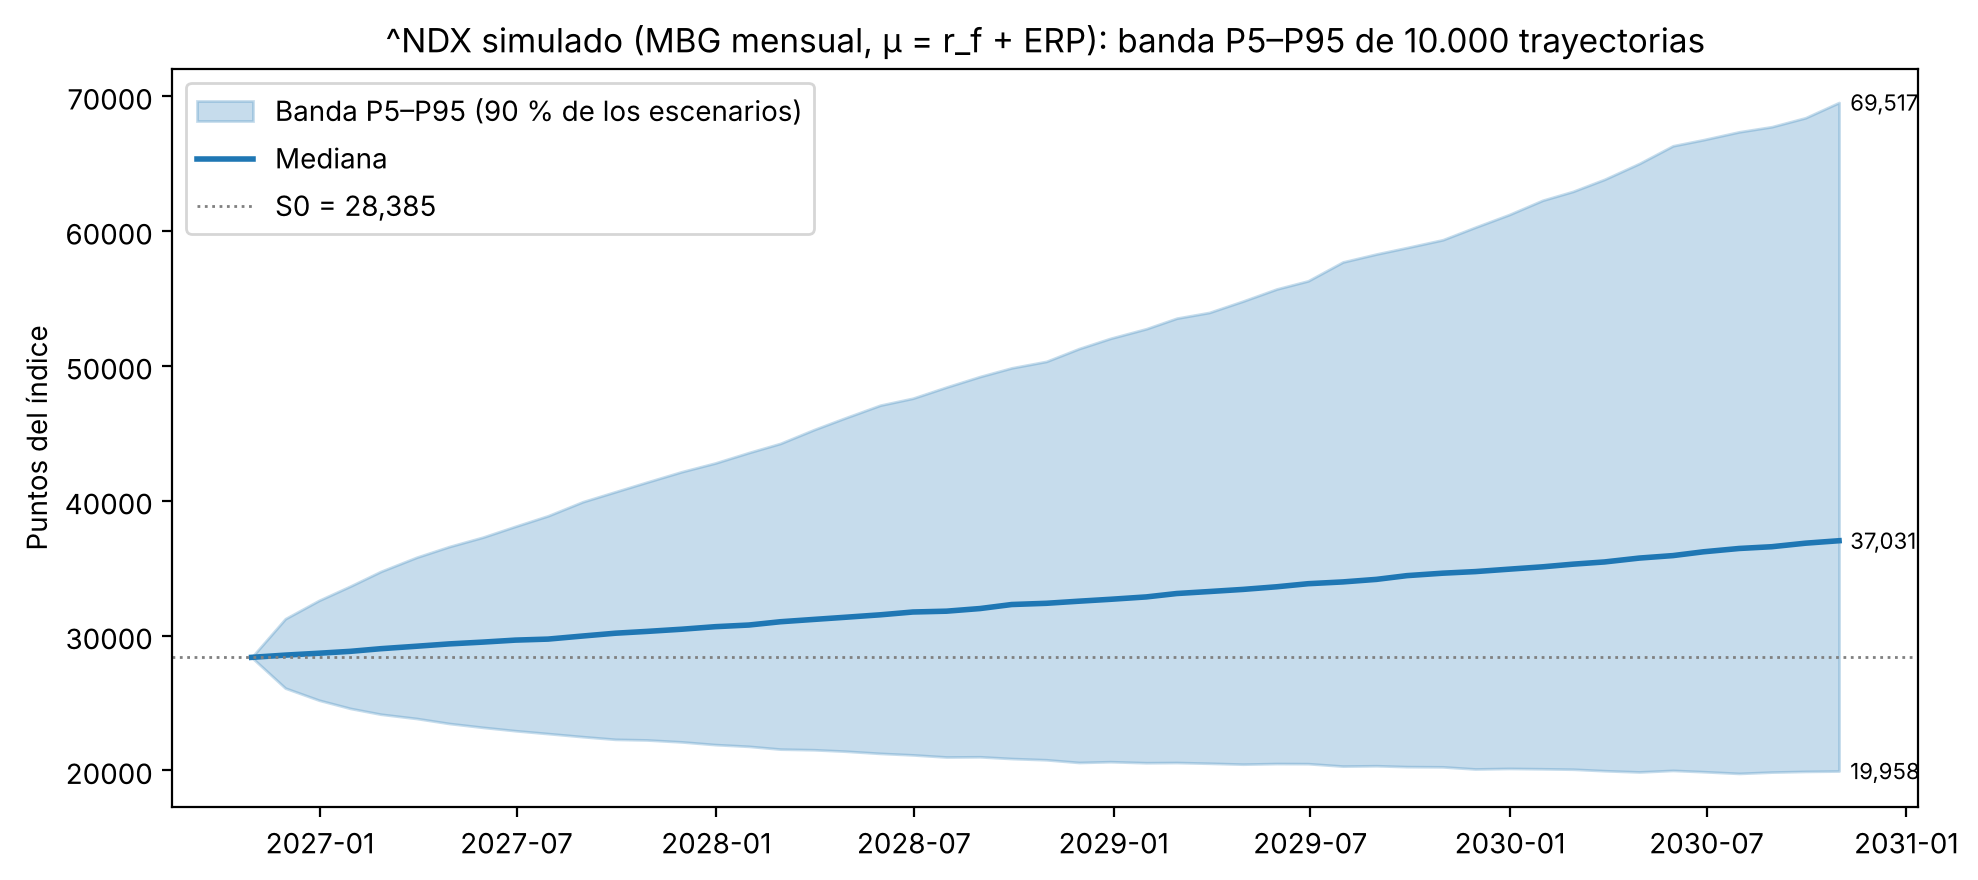

In [13]:
# Gráfico: bandas P5–P95 del índice simulado (lo que se usa para leer la simulación)
bandas = S_sim.quantile([.05, .5, .95], axis=1).T
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.fill_between(fechas, bandas[.05], bandas[.95], color="tab:blue", alpha=.25, label="Banda P5–P95 (90 % de los escenarios)")
ax.plot(fechas, bandas[.5], color="tab:blue", lw=2, label="Mediana")
ax.axhline(S0, color="gray", ls=":", lw=1, label=f"S0 = {S0:,.0f}")
for f_, v_ in [(.05, bandas[.05].iloc[-1]), (.5, bandas[.5].iloc[-1]), (.95, bandas[.95].iloc[-1])]:
    ax.annotate(f"{v_:,.0f}", (fechas[-1], v_), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8)
ax.set_title("^NDX simulado (MBG mensual, μ = r_f + ERP): banda P5–P95 de 10.000 trayectorias")
ax.set_ylabel("Puntos del índice"); ax.legend(loc="upper left")
plt.tight_layout(); fig.savefig(RAIZ / "outputs" / "figures" / "simulacion_ndx_bandas_v2.png", dpi=150); plt.show()

Lectura de la simulación: con μ = r_f + ERP la banda P5–P95 queda razonable. A 4 años la mediana deja el índice un 30 % arriba y el percentil 95 en 2,4 veces (en la v1 eran 3,8 veces, y la trayectoria más alta 8,5). En el 24 % de los escenarios el índice termina por debajo de donde arrancó, que es lo que uno esperaría de un mercado caro. Con la media histórica eso casi no pasaba (3 %), y con la neutral al riesgo pasaba demasiado (41 %), porque no tiene prima. Los chequeos de abajo muestran que los extremos son colas poco probables y que el escenario alto es incluso más moderado que lo que pasó en la última década.

¿Los extremos son razonables? Dos chequeos:

1. Qué tan probable es cada nivel del índice en oct-2030. Ojo: el índice está en puntos, no en dólares, y crece en porcentaje. Subir 10.000 puntos desde 4.800 (2016) era triplicarse; desde 28.385 es apenas un 35 %.
2. Comparar el múltiplo a 4 años simulado (S48/S0) con lo que de verdad hizo el ^NDX en todas las ventanas de 48 meses de 2016–2026.

In [14]:
# Validación 1: probabilidad de cada nivel del índice a 4 años
fin = S_sim.iloc[-1]
niveles = [S0, S0 + 10_000, 50_000, 70_000, 90_000, 100_000]
prob_niv = pd.DataFrame({"Nivel del ^NDX": niveles, "Múltiplo de S0": [n / S0 for n in niveles],
                         "Prob. de terminar por encima": [(fin > n).mean() for n in niveles]},
                        index=["S0", "S0 + 10.000 pts", "50.000", "70.000", "90.000", "100.000"])

# Validación 2: múltiplos a 4 años, históricos (ventanas móviles de 48 meses) vs. simulados
m_hist = close["^NDX"].resample("ME").last()
mult_hist = (m_hist / m_hist.shift(48)).dropna()          # S(t)/S(t−48) en la década 2016–2026
mult_sim  = fin / S0
comp_mult = pd.DataFrame({
    "Histórico 2016–2026 (48 m)": [mult_hist.min(), mult_hist.quantile(.05), mult_hist.median(), mult_hist.quantile(.95), mult_hist.max()],
    "Simulado (C)": [mult_sim.min(), mult_sim.quantile(.05), mult_sim.median(), mult_sim.quantile(.95), mult_sim.max()],
}, index=["Mínimo", "P5", "Mediana", "P95", "Máximo"])
print(f"Ventanas históricas de 48 meses: {len(mult_hist)} | último cambio a 4 años: {m_hist.iloc[-1] - m_hist.iloc[-49]:+,.0f} puntos")

prob_niv.to_csv(PROC / "probabilidad_niveles_ndx_v2.csv"); comp_mult.to_csv(PROC / "multiplos_4a_hist_vs_sim_v2.csv")
display(prob_niv.style.format({"Nivel del ^NDX": "{:,.0f}", "Múltiplo de S0": "{:.2f}", "Prob. de terminar por encima": "{:.1%}"}))
comp_mult.style.format("{:.2f}")

Ventanas históricas de 48 meses: 73 | último cambio a 4 años: +16,979 puntos


,Nivel del ^NDX,Múltiplo de S0,Prob. de terminar por encima
S0,"28,385",1.00,76.3%
S0 + 10.000 pts,"38,385",1.35,46.5%
50.000,"50,000",1.76,20.9%
70.000,"70,000",2.47,4.8%
90.000,"90,000",3.17,1.0%
100.000,"100,000",3.52,0.4%


,Histórico 2016–2026 (48 m),Simulado (C)
Mínimo,1.41,0.28
P5,1.53,0.70
Mediana,1.91,1.30
P95,2.59,2.45
Máximo,2.77,5.42


Lectura de la validación:

- La banda P5–P95 va de unos 20.000 a unos 69.500 puntos en oct-2030, con mediana cerca de 37.000. Eso es lo que usamos para leer la simulación. Los niveles de 90.000 o 100.000 puntos existen, pero son colas: probabilidad de 1 % y 0,4 %. El máximo (unos 154.000) es 1 de 10.000 trayectorias.
- Frente a la historia, el escenario alto es moderado: el P95 simulado (2,45 veces) queda por debajo del mejor caso real de la misma década (2,77 veces, que fue justo el último periodo: el ^NDX subió casi 17.000 puntos en 48 meses). Por abajo pasa lo contrario: en 2016–2026 nunca hubo 4 años con pérdida, pero eso es una década muy buena y no la regla. La simulación sí abre esa posibilidad (24 % de probabilidad de terminar por debajo de S0).
- No recortamos la cola de arriba a propósito. Como estamos cortos en futuros, las subidas fuertes son justo las que generan los llamados al margen (8.7). Quitarlas subestimaría la caja que exige la cobertura y sesgaría el valor esperado del Punto 10.

### 8.2 Contrato abierto cada mes y P&G del corto en todas las trayectorias

Roll alineado a CME: el NQ vence el tercer viernes de mar/jun/sep/dic. Para no quedarnos con un contrato a punto de vencer, al cierre del mes anterior al vencimiento (nov, feb, may, ago) pasamos al siguiente. Arrancamos con el NQZ6, que es el que tiene el F₀ = 28.534. Así siempre usamos el contrato más líquido y se renueva cada 3 meses. El detalle del roll (base, costos) va en el Punto 9.

En cada mes, el precio inicial y el final son del mismo contrato. Con ticks:

$$\text{Ticks}_t = \frac{F_{t}^{fin} - F_{t}^{ini}}{0{,}25}, \qquad \text{P\&G corto}_t = -\text{Ticks}_t \times 5 \times N$$

In [15]:
# 8.2 Calendario de vencimientos CME y precio del futuro
def tercer_viernes(anio, mes):
    d = pd.Timestamp(anio, mes, 1)
    return d + pd.Timedelta(days=(4 - d.weekday()) % 7 + 14)   # primer viernes + 2 semanas

letra = {3: "H", 6: "M", 9: "U", 12: "Z"}                      # códigos de mes de CME
venc = [(f"NQ{letra[m]}{str(a)[-1]}", tercer_viernes(a, m))
        for a in range(2026, 2032) for m in (3, 6, 9, 12) if tercer_viernes(a, m) > fechas[0]]

def contrato_del_mes(fecha_fin):
    """Contrato abierto durante el mes que cierra en fecha_fin: el primero que vence después de esa fecha."""
    return next((cod, v) for cod, v in venc if v > fecha_fin)

def precio_futuro(S_t, fecha, vencimiento):
    """F = S·e^{c(T−t)}, redondeado al tick (sirve con un número o con un arreglo)."""
    F = np.asarray(S_t) * np.exp(c * (vencimiento - fecha).days / 365)
    return np.round(F / NQ["tick"]) * NQ["tick"]

# P&G mensual del corto en las 10.000 trayectorias
S_arr  = S_sim.to_numpy()
pg_mes = np.zeros((n_mes, n_sim))
contratos_mes = []
for t in range(1, n_mes + 1):
    cod, v = contrato_del_mes(fechas[t])
    contratos_mes.append(cod)
    F_ini = precio_futuro(S_arr[t - 1], fechas[t - 1], v)
    F_fin = precio_futuro(S_arr[t], fechas[t], v)
    pg_mes[t - 1] = -(F_fin - F_ini) / NQ["tick"] * NQ["valor_tick"] * N    # corto: −ticks × USD 5 × N

PG_acum = np.vstack([cero, np.cumsum(pg_mes, axis=0)])   # P&G acumulado de los futuros (USD)
V_cub   = V_sin + PG_acum                                 # portafolio cubierto = acciones + futuros

print("Contratos usados:", " → ".join(dict.fromkeys(contratos_mes)))

Contratos usados: NQZ6 → NQH7 → NQM7 → NQU7 → NQZ7 → NQH8 → NQM8 → NQU8 → NQZ8 → NQH9 → NQM9 → NQU9 → NQZ9 → NQH0 → NQM0 → NQU0 → NQZ0


### 8.3 El peor escenario: portafolio en pérdida por una caída del mercado

La idea es ver para qué sirven los futuros: cuando el mercado se cae y arrastra al portafolio, ¿cuánto de esa pérdida compensa el corto? Por eso el peor escenario se escoge por el lado del mercado, que es el riesgo que cubre el futuro:

- Escenario principal: las trayectorias en que el ^NDX termina alrededor de su percentil 5 a 4 años (entre el P4 y el P6, coherente con el VaR al 95 %). De ese grupo tomamos la trayectoria típica, la del valor mediano del portafolio sin cobertura (como el grupo tiene un número par de trayectorias, tomamos la de arriba de las dos del medio).
- Sensibilidad: lo mismo alrededor del percentil 1 del índice (entre el P0,5 y el P1,5, coherente con el VaR al 99 %).

Tomar la trayectoria típica dentro del grupo evita escoger una donde, por pura suerte, las acciones se salvaron o se hundieron por su cuenta (el riesgo propio, que el futuro no cubre). Además del caso puntual, mostramos el promedio de todo el grupo.

In [16]:
# 8.3 Peor escenario de mercado: índice en el percentil 5 (principal) y en el percentil 1 (sensibilidad)
fin_idx = pd.Series(S_arr[-1])                        # ^NDX al final de cada trayectoria
fin_sin = pd.Series(V_sin[-1])                        # portafolio sin cobertura al final

def escenario_mercado(pct, ancho):
    """Trayectorias con el índice final entre los percentiles pct ± ancho/2; devuelve la típica y el grupo."""
    lo, hi = fin_idx.quantile(pct - ancho / 2), fin_idx.quantile(pct + ancho / 2)
    grupo = fin_idx[(fin_idx >= lo) & (fin_idx <= hi)].index
    # la de valor sin cobertura mediano. Como el grupo tiene un número par de trayectorias, hay dos "en la mitad";
    # tomamos la de arriba (interpolation="higher") para que la elección no dependa de decimales del computador
    mediana = fin_sin[grupo].quantile(.5, interpolation="higher")
    k = int((fin_sin[grupo] - mediana).abs().idxmin())
    return k, grupo

k5, g5 = escenario_mercado(.05, .02)                  # P4–P6
k1, g1 = escenario_mercado(.01, .01)                  # P0,5–P1,5

filas = {}
for nombre, k, g in [("Percentil 5 del índice", k5, g5), ("Percentil 1 del índice", k1, g1)]:
    filas[nombre] = {"Trayectoria": k, "^NDX var. 4 años": S_arr[-1, k] / S0 - 1,
                     "V sin cobertura": V_sin[-1, k], "P&G futuros": PG_acum[-1, k], "V cubierto": V_cub[-1, k],
                     "Pérdida sin cobertura": V_sin[-1, k] - Vp, "Pérdida cubierto": V_cub[-1, k] - Vp,
                     "Grupo: n.º trayectorias": len(g), "Grupo: V sin cobertura prom.": V_sin[-1, g].mean(),
                     "Grupo: V cubierto prom.": V_cub[-1, g].mean()}
peores = pd.DataFrame(filas).T
peores.to_csv(PROC / "peor_escenario_v2.csv")

# Tabla legible: USD con separador de miles, variación del índice en %, enteros sin decimales
fmt_p = {c_: ("{:+.2%}" if "var." in c_ else "{:,.0f}" if ("n.º" in c_ or c_ == "Trayectoria") else
              "{:+,.0f}" if ("Pérdida" in c_ or "P&G" in c_) else "{:,.0f}") for c_ in peores.columns}
peores.T.apply(lambda col: pd.Series([fmt_p[i].format(v) for i, v in col.items()], index=col.index))

,Percentil 5 del índice,Percentil 1 del índice
Trayectoria,835,"4,659"
^NDX var. 4 años,-27.25%,-45.80%
V sin cobertura,"32,113,166","27,179,184"
P&G futuros,"+7,901,355","+10,996,920"
V cubierto,"40,014,521","38,176,104"
Pérdida sin cobertura,"-2,886,834","-7,820,816"
Pérdida cubierto,"+5,014,521","+3,176,104"
Grupo: n.º trayectorias,200,100
Grupo: V sin cobertura prom.,"33,447,948","27,807,598"
Grupo: V cubierto prom.,"41,559,738","38,739,430"


### 8.4 Cuenta de margen mes a mes (peor escenario: mercado en el percentil 5)

Misma lógica del Excel de ejemplo y de la Clase 18:

- El mes 0 arranca con $VGI_0$ (USD 1.430.474,10 para 33 contratos).
- Saldo del mes = saldo anterior + reposición del mes anterior + P&G del corto.
- Si el saldo queda por debajo de $VGM$ (USD 1.300.431), hay llamado al margen y se repone hasta $VGI_0$.
- No se retiran excedentes (igual que en el Excel). Tampoco se cuentan intereses sobre el saldo, ni costos (esos van en el Punto 9).

In [17]:
# 8.4 Cuenta de margen por ticks para una trayectoria (columnas que pide el enunciado)
def cuenta_margen(k):
    filas, saldo, mc_ant = [], VGI0, 0.0
    for t in range(1, n_mes + 1):
        cod, v = contrato_del_mes(fechas[t])
        F_ini = float(precio_futuro(S_arr[t - 1, k], fechas[t - 1], v))   # precio inicial del mes
        F_fin = float(precio_futuro(S_arr[t, k], fechas[t], v))           # precio final del mes
        dF    = F_fin - F_ini                                             # variación (puntos)
        ticks = dF / NQ["tick"]                                           # n.º de ticks = ΔF / tick
        pg_largo = ticks * NQ["valor_tick"] * N                           # ticks × USD 5 × N
        pg_corto = -pg_largo                                              # nuestra posición
        saldo = saldo + mc_ant + pg_corto                                 # liquidación mensual
        mc = VGI0 - saldo if saldo < VGM else 0.0                         # reposición hasta VGI0
        filas.append({"Mes": t, "Trimestre": f"T{(t - 1) // 3 + 1}", "Fecha": fechas[t].date(), "Contrato": cod,
                      "S índice": S_arr[t, k], "F inicial": F_ini, "F final": F_fin, "ΔF": dF, "Ticks": ticks,
                      "P&G largo": pg_largo, "P&G corto": pg_corto, "Saldo margen": saldo,
                      "Margin call": saldo < VGM, "Reposición": mc,
                      "V sin cobertura": V_sin[t, k], "V cubierto": V_cub[t, k]})
        mc_ant = mc
    return pd.DataFrame(filas).set_index("Mes")

cuenta = cuenta_margen(k5)
cuenta.to_csv(PROC / "cuenta_margen_mensual_v2.csv")
pd.set_option("display.max_rows", 60)
cuenta.drop(columns=["V sin cobertura", "V cubierto"]).style.format(
    {"S índice": "{:,.2f}", "F inicial": "{:,.2f}", "F final": "{:,.2f}", "ΔF": "{:+,.2f}", "Ticks": "{:+,.0f}",
     "P&G largo": "{:+,.0f}", "P&G corto": "{:+,.0f}", "Saldo margen": "{:,.0f}", "Reposición": "{:,.0f}"})

,Trimestre,Fecha,Contrato,S índice,F inicial,F final,ΔF,Ticks,P&G largo,P&G corto,Saldo margen,Margin call,Reposición
Mes,,,,,,,,,,,,,
1,T1,2026-11-30,NQZ6,"28,226.66","28,534.00","28,281.00",-253.00,"-1,012","-166,980","+166,980","1,597,454",False,0
2,T1,2026-12-31,NQH7,"30,258.19","28,557.75","30,511.75","+1,954.00","+7,816","+1,289,640","-1,289,640","307,814",True,"1,122,660"
3,T1,2027-01-29,NQH7,"29,062.76","30,511.75","29,215.50","-1,296.25","-5,185","-855,525","+855,525","2,285,999",False,0
4,T2,2027-02-26,NQH7,"28,958.46","29,215.50","29,023.50",-192.00,-768,"-126,720","+126,720","2,412,719",False,0
5,T2,2027-03-31,NQM7,"27,415.22","29,307.50","27,647.75","-1,659.75","-6,639","-1,095,435","+1,095,435","3,508,154",False,0
6,T2,2027-04-30,NQM7,"26,885.52","27,647.75","27,026.75",-621.00,"-2,484","-409,860","+409,860","3,918,014",False,0
7,T3,2027-05-31,NQM7,"28,306.44","27,026.75","28,361.00","+1,334.25","+5,337","+880,605","-880,605","3,037,409",False,0
8,T3,2027-06-30,NQU7,"28,908.50","28,638.50","29,153.75",+515.25,"+2,061","+340,065","-340,065","2,697,344",False,0
9,T3,2027-07-30,NQU7,"27,635.79","29,153.75","27,781.00","-1,372.75","-5,491","-906,015","+906,015","3,603,359",False,0


In [18]:
# 8.5 Resumen por trimestre (T1–T16) y totales del peor escenario
def resumen_trimestral(cta):
    return cta.groupby("Trimestre", sort=False).agg(
        Contrato=("Contrato", "last"), S_final=("S índice", "last"), F_final=("F final", "last"),
        Ticks=("Ticks", "sum"), PG_largo=("P&G largo", "sum"), PG_corto=("P&G corto", "sum"),
        Margin_calls=("Margin call", "sum"), Reposicion=("Reposición", "sum"), Saldo_final=("Saldo margen", "last"),
        V_sin=("V sin cobertura", "last"), V_cub=("V cubierto", "last"))

trim = resumen_trimestral(cuenta)
trim.to_csv(PROC / "cuenta_margen_trimestral_v2.csv")

cuenta1 = cuenta_margen(k1)                                   # sensibilidad: percentil 1
cuenta1.to_csv(PROC / "cuenta_margen_mensual_p1_v2.csv")
for nombre, cta in [("Percentil 5", cuenta), ("Percentil 1", cuenta1)]:
    print(f"{nombre}: P&G del corto = {cta['P&G corto'].sum():+,.0f} USD | "
          f"llamados = {int(cta['Margin call'].sum())} de {n_mes} meses | repuesto = {cta['Reposición'].sum():,.0f} USD | "
          f"saldo final = {cta['Saldo margen'].iloc[-1]:,.0f} USD")

trim.style.format({"S_final": "{:,.2f}", "F_final": "{:,.2f}", "Ticks": "{:+,.0f}", "PG_largo": "{:+,.0f}",
                   "PG_corto": "{:+,.0f}", "Reposicion": "{:,.0f}", "Saldo_final": "{:,.0f}",
                   "V_sin": "{:,.0f}", "V_cub": "{:,.0f}"})

Percentil 5: P&G del corto = +7,901,355 USD | llamados = 1 de 48 meses | repuesto = 1,122,660 USD | saldo final = 10,454,489 USD
Percentil 1: P&G del corto = +10,996,920 USD | llamados = 2 de 48 meses | repuesto = 770,385 USD | saldo final = 13,197,779 USD


,Contrato,S_final,F_final,Ticks,PG_largo,PG_corto,Margin_calls,Reposicion,Saldo_final,V_sin,V_cub
Trimestre,,,,,,,,,,,
T1,NQH7,"29,062.76","29,215.50","+1,619","+267,135","-267,135",1,"1,122,660","2,285,999","35,276,953","35,009,818"
T2,NQM7,"26,885.52","27,026.75","-9,891","-1,632,015","+1,632,015",0,0,"3,918,014","33,936,254","35,301,134"
T3,NQU7,"27,635.79","27,781.00","+1,907","+314,655","-314,655",0,0,"3,603,359","37,002,995","38,053,220"
T4,NQZ7,"28,595.81","28,746.00","+2,864","+472,560","-472,560",0,0,"3,130,799","36,086,981","36,664,646"
T5,NQH8,"28,568.58","28,709.50","-1,368","-225,720","+225,720",0,0,"3,356,519","32,624,312","33,427,697"
T6,NQM8,"28,911.28","29,063.25",+313,"+51,645","-51,645",0,0,"3,304,874","31,851,472","32,603,212"
T7,NQU8,"28,839.07","28,981.25","-1,418","-233,970","+233,970",0,0,"3,538,844","36,366,277","37,351,987"
T8,NQZ8,"29,492.23","29,634.50","+1,549","+255,585","-255,585",0,0,"3,283,259","36,526,288","37,256,413"
T9,NQH9,"27,242.31","27,370.75","-10,182","-1,680,030","+1,680,030",0,0,"4,963,289","31,239,433","33,649,588"


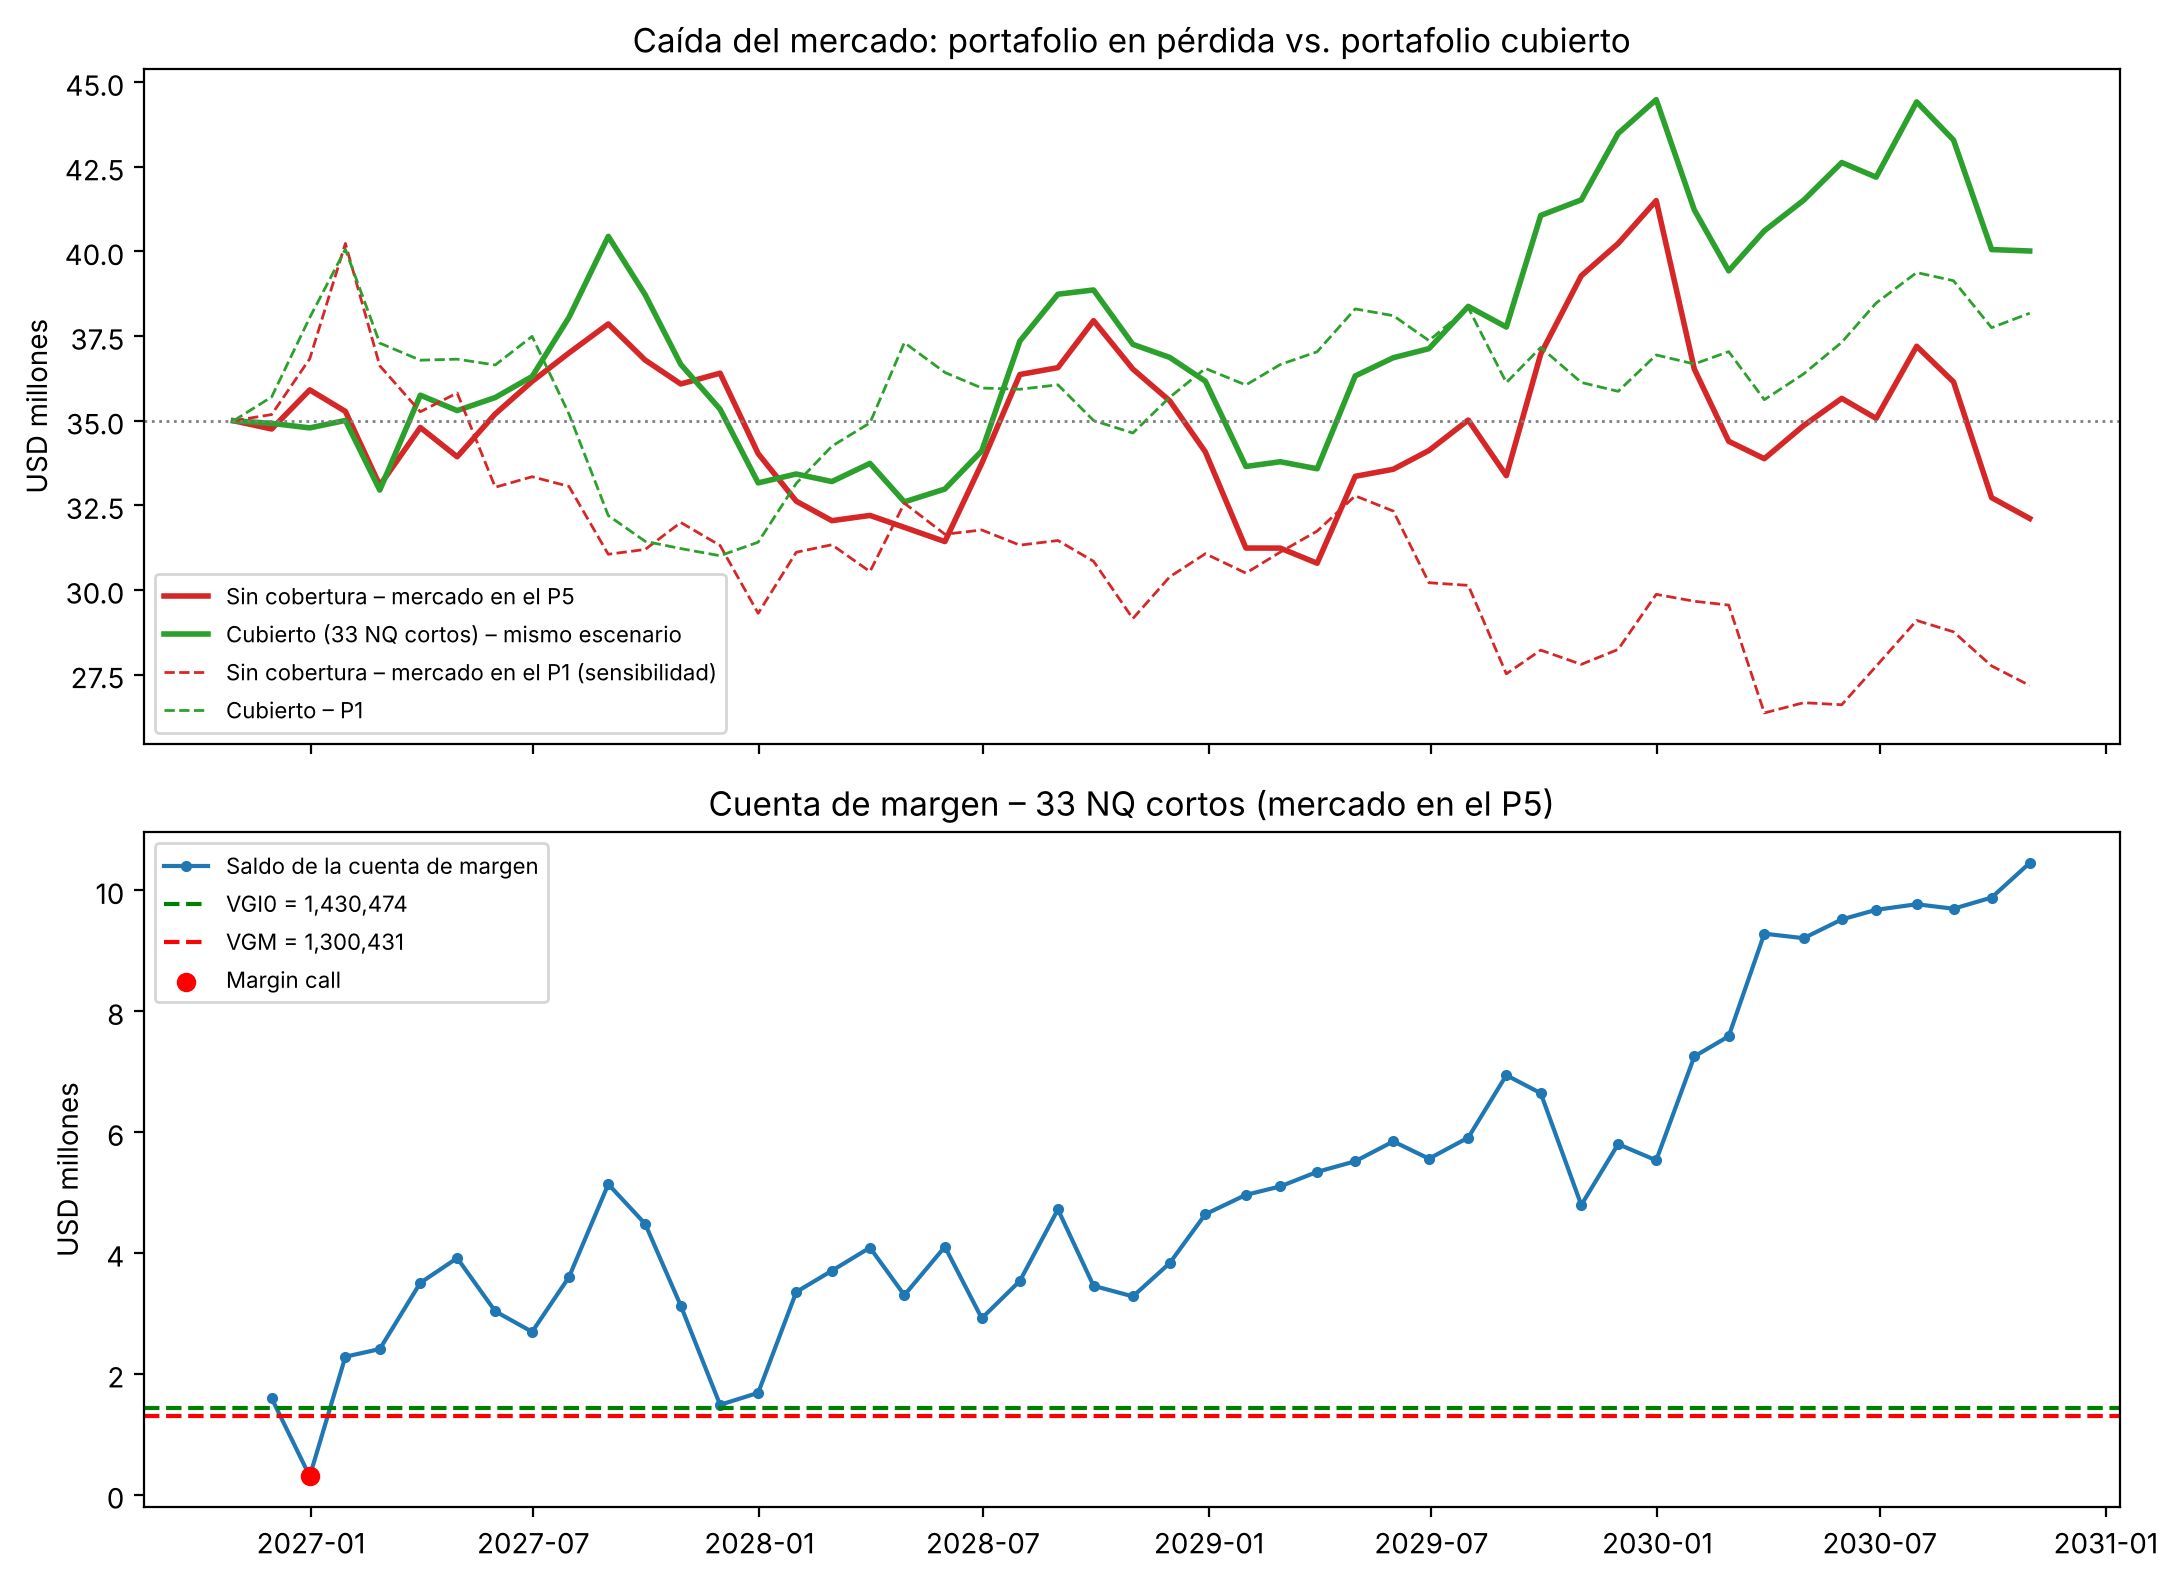

In [19]:
# 8.6 Gráfico: peor escenario sin cobertura vs. portafolio cubierto, y cuenta de margen
fig, ax = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
ax[0].plot(fechas, V_sin[:, k5] / 1e6, color="tab:red", lw=2, label="Sin cobertura – mercado en el P5")
ax[0].plot(fechas, V_cub[:, k5] / 1e6, color="tab:green", lw=2, label="Cubierto (33 NQ cortos) – mismo escenario")
ax[0].plot(fechas, V_sin[:, k1] / 1e6, color="tab:red", lw=1, ls="--", label="Sin cobertura – mercado en el P1 (sensibilidad)")
ax[0].plot(fechas, V_cub[:, k1] / 1e6, color="tab:green", lw=1, ls="--", label="Cubierto – P1")
ax[0].axhline(Vp / 1e6, color="gray", ls=":", lw=1)
ax[0].set_ylabel("USD millones"); ax[0].legend(fontsize=8)
ax[0].set_title("Caída del mercado: portafolio en pérdida vs. portafolio cubierto")
ax[1].plot(fechas[1:], cuenta["Saldo margen"] / 1e6, marker="o", ms=3, label="Saldo de la cuenta de margen")
ax[1].axhline(VGI0 / 1e6, color="green", ls="--", label=f"VGI0 = {VGI0:,.0f}")
ax[1].axhline(VGM / 1e6, color="red", ls="--", label=f"VGM = {VGM:,.0f}")
mc_f = cuenta[cuenta["Margin call"]]
ax[1].scatter(pd.to_datetime(mc_f["Fecha"]), mc_f["Saldo margen"] / 1e6, color="red", zorder=3, label="Margin call")
ax[1].set_ylabel("USD millones"); ax[1].legend(fontsize=8)
ax[1].set_title("Cuenta de margen – 33 NQ cortos (mercado en el P5)")
plt.tight_layout(); fig.savefig(RAIZ / "outputs" / "figures" / "peor_escenario_cubierto_v2.png", dpi=150); plt.show()

### 8.7 ¿Cuánta caja exige la cuenta de margen? (las 10.000 trayectorias)

Una sola trayectoria no dice cuánta liquidez hay que tener lista. Corremos la misma cuenta de margen en todas.

In [20]:
# 8.7 Llamados al margen y reposición en las 10.000 trayectorias
saldo = np.full(n_sim, VGI0); mc_ant = np.zeros(n_sim)
n_llamados = np.zeros(n_sim); repos_total = np.zeros(n_sim); repos_max_mes = np.zeros(n_sim)
for t in range(n_mes):
    saldo = saldo + mc_ant + pg_mes[t]
    mc = np.where(saldo < VGM, VGI0 - saldo, 0.0)
    n_llamados += mc > 0; repos_total += mc; repos_max_mes = np.maximum(repos_max_mes, mc)
    mc_ant = mc

liquidez = pd.DataFrame({"Llamados (de 48 meses)": n_llamados, "Reposición total (USD)": repos_total,
                         "Mayor reposición en un mes (USD)": repos_max_mes})
liq = liquidez.quantile([.05, .5, .95]).T
liq.insert(0, "Promedio", liquidez.mean())
liq.columns = ["Promedio", "P5", "Mediana", "P95"]
liq.to_csv(PROC / "liquidez_margen_v2.csv")

np.savez_compressed(PROC / "simulacion_v2.npz", S=S_arr, V_sin=V_sin, PG_acum=PG_acum, pg_mes=pg_mes,
                    fechas=fechas.strftime("%Y-%m-%d").to_numpy().astype("U10"))   # insumo de los Puntos 9 a 12
liq.style.format("{:,.0f}")

,Promedio,P5,Mediana,P95
Llamados (de 48 meses),8,0,7,18
Reposición total (USD),"9,081,433",0,"6,840,818","26,163,580"
Mayor reposición en un mes (USD),"2,219,572",0,"2,058,458","4,625,948"


Lectura del Punto 8:

- Para qué sirven los futuros: en el escenario principal el Nasdaq cae 27 % en 4 años y el portafolio sin cobertura termina en USD 32,1 M (pierde USD 2,9 M). Ahí el corto de 33 NQ gana USD 7,9 M y el portafolio cubierto termina en USD 40,0 M. En el escenario del percentil 1 (índice −46 %), el sin cobertura pierde USD 7,8 M y el cubierto termina en USD 38,2 M, porque el corto gana USD 11,0 M. Promediando todo el grupo de trayectorias con esa caída, la conclusión es la misma: sin cobertura USD 33,4 M y cubierto USD 41,6 M.
- ¿Por qué el futuro gana más de lo que pierden las acciones? Por dos cosas. Primero, con β = 0,54 el portafolio cae menos que el índice, y una parte de su retorno (la de r_f) no depende del mercado. Segundo, el corto se gana el costo de llevar: cada trimestre se vende un futuro que está por encima del índice (F > S, c = 3,9 %) y ese precio converge hacia el índice. Al neutralizar el mercado, el portafolio cubierto queda cerca de lo que daría la tasa libre de riesgo (USD 35 M × 1,04929⁴ ≈ USD 42,4 M). Eso lo retomamos en el Punto 10.
- La cuenta de margen en el escenario principal: como el mercado cae, el corto va ganando y el saldo sube hasta USD 10,5 M. Solo hubo un llamado al margen, en el mes 2, cuando el índice subió 7 % de una (USD 1,12 M de reposición). Esto confirma lo del 7.2: los llamados llegan en los meses en que el mercado sube, no en las caídas.
- La caja que hay que tener lista, en las 10.000 trayectorias: en promedio hay 7,6 llamados en 48 meses y se reponen USD 9,1 M en total. En el 5 % de los peores casos para la cuenta (cuando el mercado sube fuerte) son 18 llamados y USD 26,2 M. Este es el verdadero costo de la cobertura: no se paga en rentabilidad en las caídas, sino en liquidez cuando el mercado sube.
- Lo que el futuro no hace: si el portafolio pierde por sus propias acciones y no por el mercado, el corto no ayuda (R² = 0,33, como vimos en el 7.4 con sep-2022). Por eso aquí escogimos escenarios donde la pérdida viene del mercado, que es el riesgo que se está cubriendo.
- Supuestos: N = 33 fijo los 4 años, liquidación mensual (en la práctica es diaria), sin intereses sobre el saldo de margen y sin costos de transacción (los costos y la base del roll van en el Punto 9).

### 8.8 Comparativa: crecimiento con prima de riesgo (C) vs. neutral al riesgo (B)

¿Qué pasaría si el índice creciera a la tasa neutral al riesgo, μ = c = 3,90 %, que es la que está metida en el precio del futuro? Corremos todo el Punto 8 otra vez con esa deriva y con los mismos choques aleatorios (Z y ε), para que la única diferencia sea el crecimiento del índice.

In [21]:
# 8.8 Mismo azar, dos derivas: C (r_f + ERP, la elegida) vs. B (neutral al riesgo, μ = c)
def correr_p8(deriva_idx):
    """Simula índice, portafolio, P&G del corto (N fijo) y cuenta de margen en las 10.000 trayectorias."""
    ri = deriva_idx + sig_m * Z
    rp = rf_m + beta_p * (ri + q_m - rf_m) + sig_e * E
    S_ = S0 * np.exp(np.vstack([cero, np.cumsum(ri, axis=0)]))
    Vs = Vp * np.exp(np.vstack([cero, np.cumsum(rp, axis=0)]))
    pg = np.zeros((n_mes, n_sim))
    for t in range(1, n_mes + 1):
        cod, v = contrato_del_mes(fechas[t])
        pg[t - 1] = -(precio_futuro(S_[t], fechas[t], v) - precio_futuro(S_[t - 1], fechas[t - 1], v)) / NQ["tick"] * NQ["valor_tick"] * N
    PG = np.vstack([cero, np.cumsum(pg, axis=0)]); Vc = Vs + PG
    saldo = np.full(n_sim, VGI0); mca = np.zeros(n_sim); nl = np.zeros(n_sim); rep = np.zeros(n_sim)
    for t in range(n_mes):
        saldo = saldo + mca + pg[t]; mc = np.where(saldo < VGM, VGI0 - saldo, 0.0)
        nl += mc > 0; rep += mc; mca = mc
    fi, fs = pd.Series(S_[-1]), pd.Series(Vs[-1])
    lo, hi = fi.quantile(.04), fi.quantile(.06); g = fi[(fi >= lo) & (fi <= hi)].index
    k = int((fs[g] - fs[g].quantile(.5, interpolation="higher")).abs().idxmin())   # misma regla del 8.3 (P5 del índice)
    m_ = S_[-1] / S0
    return {"Índice S48/S0: P5": np.quantile(m_, .05), "Índice S48/S0: mediana": np.median(m_),
            "Índice S48/S0: P95": np.quantile(m_, .95), "Prob. índice < S0": (m_ < 1).mean(),
            "E[V] sin cobertura (USD)": Vs[-1].mean(), "E[V] cubierto (USD)": Vc[-1].mean(),
            "E[P&G del corto] (USD)": PG[-1].mean(),
            "Prob. de pérdida sin cobertura": (Vs[-1] < Vp).mean(), "Prob. de pérdida cubierto": (Vc[-1] < Vp).mean(),
            "Peor escenario (P5 índice): ^NDX": S_[-1, k] / S0 - 1,
            "Peor escenario: V sin cobertura (USD)": Vs[-1, k], "Peor escenario: V cubierto (USD)": Vc[-1, k],
            "Llamados al margen (promedio)": nl.mean(), "Reposición total promedio (USD)": rep.mean(),
            "Reposición total P95 (USD)": np.quantile(rep, .95)}

deriva_B = (c - 0.5 * sig_a**2) * dt
comp_BC = pd.DataFrame({"C. r_f + ERP (elegida)": correr_p8(deriva), "B. Neutral al riesgo (μ = c)": correr_p8(deriva_B)})
mu_total_B = np.exp(c) - 1 + q                         # retorno total del mercado que implica B
print(f"Retorno total del mercado: C = {rf + ERP:.2%} | B = {mu_total_B:.2%}  (r_f = {rf:.3%}) "
      f"-> prima implícita en B = {mu_total_B - rf:+.2%}")
comp_BC.to_csv(PROC / "comparativa_B_vs_C_v2.csv")
fmt = {k: ("{:.2%}" if ("Prob." in k or "^NDX" in k) else "{:,.0f}" if "USD" in k else "{:.2f}") for k in comp_BC.index}
comp_BC.apply(lambda col: pd.Series([fmt[i].format(v) for i, v in col.items()], index=col.index))

Retorno total del mercado: C = 9.34% | B = 4.44%  (r_f = 4.929%) -> prima implícita en B = -0.49%


,C. r_f + ERP (elegida),B. Neutral al riesgo (μ = c)
Índice S48/S0: P5,0.70,0.59
Índice S48/S0: mediana,1.30,1.09
Índice S48/S0: P95,2.45,2.04
Prob. índice < S0,23.74%,41.23%
E[V] sin cobertura (USD),"47,694,996","43,214,899"
E[V] cubierto (USD),"43,609,537","43,227,039"
E[P&G del corto] (USD),"-4,085,459","12,141"
Prob. de pérdida sin cobertura,24.44%,33.90%
Prob. de pérdida cubierto,29.16%,28.42%
Peor escenario (P5 índice): ^NDX,-27.25%,-39.39%


Lectura de la comparativa:

- Con B, cubrirse no cuesta nada en promedio: el corto gana cero en promedio y el valor esperado es el mismo con o sin cobertura (unos USD 43,2 M). Eso pasa por construcción: en el mundo neutral al riesgo el futuro está bien valorado y nadie gana un premio por tener acciones.
- Con C, cubrirse cuesta en promedio unos USD 4,1 M (E[V] de 47,7 M sin cubrir contra 43,6 M cubierto). Ese es el precio del seguro: se renuncia a la prima de riesgo del mercado a cambio de protección en las caídas.
- En las caídas el futuro hace su trabajo con cualquiera de las dos: en el peor escenario de mercado el cubierto termina cerca de USD 39–40 M, aunque el índice caiga 27 % (C) o 39 % (B).
- ¿Por qué nos quedamos con C? B le da al mercado un retorno total de 4,44 %, menor que nuestra r_f de 4,93 %. Eso sería una prima negativa: nadie compraría acciones esperando ganar menos que el bono. Pasa porque c sale de la tasa de corto plazo que hay en el precio del futuro, no del bono a 10 años que usamos en todo el lab. B sirve para valorar el futuro; para proyectar escenarios y medir el riesgo se usa C.
- Lo que no cambia con ninguna: la probabilidad de que el portafolio cubierto termine por debajo de USD 35 M sigue en 28–29 %. Es el riesgo propio de las acciones (R² = 0,33), que el futuro no quita.

## Punto 9 – Roll-over trimestral, riesgo de base y costos (R11 – 10 %)

La estrategia es la del enunciado y la asesoría del 04/11: corto absoluto los 4 años, 33 contratos fijos y renovación cada 3 meses. El roll va alineado a CME: al cierre de nov, feb, may y ago se cierra el contrato que está por vencer y se abre el siguiente (NQZ6 → NQH7 → … → NQZ0). Son 17 contratos y 16 renovaciones. El último (NQZ0) se cierra el 30/10/2030, cuando termina la cobertura.

¿Por qué no en las fechas de nuestros trimestres (ene/abr/jul/oct)? Porque el NQZ6 vence el 18/12/2026, antes del cierre de nuestro primer trimestre. Tocaría arrancar con el NQH7 y ya no serviría el F₀ del NQZ6. Igual agrupamos todo en los trimestres de inversión T1–T16.

P&G realizado de cada contrato (corto):

$$P\&G_k = (F_{apertura} - F_{cierre}) \times Q_F \times N$$

Con la liquidación mensual del Punto 8 ese resultado ya se fue pagando mes a mes; el roll solo lo "cierra" y abre el contrato nuevo a otro precio.

Riesgo de base (Clase 20): $b_t = S_t - F_t$. El P&G de cada contrato se parte en dos:

$$P\&G_k = \underbrace{-Q_F N\,(S_{cierre} - S_{apertura})}_{\text{spot: la cobertura}} + \underbrace{Q_F N\,(b_{cierre} - b_{apertura})}_{\text{base: roll yield}}$$

Como el futuro está por encima del índice (contango, c = 3,90 %), la base arranca negativa en cada contrato y se va acercando a cero. El corto vende "caro" y recompra más cerca del índice, y esa diferencia es una ganancia que se repite en cada roll.

Costos por contrato y por lado (abrir o cerrar):

| Concepto | USD | Fuente |
|---|---|---|
| Comisión del broker | 0,850 | [Interactive Brokers – Futures commissions](https://www.interactivebrokers.com/en/pricing/commissions-futures.php) (≤ 1.000 contratos/mes) |
| Tarifa de bolsa CME Globex (NQ, no miembro) | 1,386 | [IBKR – CME exchange fees](https://www.interactivebrokers.com/en/index.php?f=269&nhf=T) |
| Tarifa regulatoria NFA | 0,011 | IBKR – CME exchange fees |
| Deslizamiento (supuesto: 1 tick por lado) | 5,000 | Supuesto propio |
| Total | 7,247 | |

In [22]:
# 9.1 Roll-over en el escenario principal (mercado en el P5, trayectoria k5 del Punto 8)
costo_lado = 0.85 + 1.386 + 0.011 + 1 * NQ["valor_tick"]   # comisión + tasa CME + NFA + 1 tick de deslizamiento

rolls = []
for cod, g in cuenta.groupby("Contrato", sort=False):
    m_ini, m_fin = g.index.min(), g.index.max()             # primer y último mes con el contrato abierto
    f_ap, f_ci = fechas[m_ini - 1], fechas[m_fin]           # fecha de apertura y de cierre
    F_ap, F_ci = g["F inicial"].iloc[0], g["F final"].iloc[-1]
    S_ap, S_ci = S_arr[m_ini - 1, k5], S_arr[m_fin, k5]
    pg = (F_ap - F_ci) * NQ["Q_F"] * N                      # P&G realizado del corto
    comp_spot = -NQ["Q_F"] * N * (S_ci - S_ap)              # parte que compensa el movimiento del índice
    rolls.append({"Contrato": cod, "Apertura": f_ap.date(), "Cierre": f_ci.date(), "Meses": len(g),
                  "Trimestre de cierre": g["Trimestre"].iloc[-1],
                  "F apertura": F_ap, "F cierre": F_ci, "S apertura": S_ap, "S cierre": S_ci,
                  "Base apertura": S_ap - F_ap, "Base cierre": S_ci - F_ci,
                  "P&G realizado": pg, "Comp. spot": comp_spot, "Comp. base": pg - comp_spot,
                  "Costos": 2 * N * costo_lado})            # se abren y se cierran 33 contratos

rolls = pd.DataFrame(rolls).set_index("Contrato")
rolls["Spread roll (pts)"] = rolls["F apertura"] - rolls["F cierre"].shift(1)   # contrato nuevo vs. el que se cierra, mismo día
rolls.to_csv(PROC / "rollover_contratos_v2.csv")

print(f"Costo por contrato y por lado = USD {costo_lado:.3f} | lados negociados = {2 * N * len(rolls):,}")
print(f"Control: suma P&G realizado = {rolls['P&G realizado'].sum():+,.0f} vs. P&G mensual del Punto 8 = {cuenta['P&G corto'].sum():+,.0f}")
rolls.style.format({c_: "{:,.2f}" for c_ in ["F apertura", "F cierre", "S apertura", "S cierre", "Base apertura", "Base cierre", "Spread roll (pts)"]}
                   | {c_: "{:+,.0f}" for c_ in ["P&G realizado", "Comp. spot", "Comp. base"]} | {"Costos": "{:,.0f}"}, na_rep="—")

Costo por contrato y por lado = USD 7.247 | lados negociados = 1,122
Control: suma P&G realizado = +7,901,355 vs. P&G mensual del Punto 8 = +7,901,355


,Apertura,Cierre,Meses,Trimestre de cierre,F apertura,F cierre,S apertura,S cierre,Base apertura,Base cierre,P&G realizado,Comp. spot,Comp. base,Costos,Spread roll (pts)
Contrato,,,,,,,,,,,,,,,
NQZ6,2026-10-30,2026-11-30,1,T1,"28,534.00","28,281.00","28,384.85","28,226.66",-149.15,-54.34,"+166,980","+104,403","+62,577",478,—
NQH7,2026-11-30,2027-02-26,3,T2,"28,557.75","29,023.50","28,226.66","28,958.46",-331.09,-65.04,"-307,395","-482,987","+175,592",478,276.75
NQM7,2027-02-26,2027-05-31,3,T3,"29,307.50","28,361.00","28,958.46","28,306.44",-349.04,-54.56,"+624,690","+430,331","+194,359",478,284.00
NQU7,2027-05-31,2027-08-31,3,T4,"28,638.50","25,452.75","28,306.44","25,406.59",-332.06,-46.16,"+2,102,595","+1,913,902","+188,693",478,277.50
NQZ7,2027-08-31,2027-11-30,3,T5,"25,701.75","31,231.25","25,406.59","31,174.52",-295.16,-56.73,"-3,649,470","-3,806,834","+157,364",478,249.00
NQH8,2027-11-30,2028-02-29,3,T6,"31,536.75","28,176.50","31,174.52","28,125.26",-362.23,-51.24,"+2,217,765","+2,012,510","+205,255",478,305.50
NQM8,2028-02-29,2028-05-31,3,T7,"28,452.00","27,851.00","28,125.26","27,803.36",-326.74,-47.64,"+396,660","+212,457","+184,203",478,275.50
NQU8,2028-05-31,2028-08-31,3,T8,"28,123.50","27,188.25","27,803.36","27,144.68",-320.14,-43.57,"+617,265","+434,728","+182,537",478,272.50
NQZ8,2028-08-31,2028-11-30,3,T9,"27,454.25","28,799.25","27,144.68","28,753.08",-309.57,-46.17,"-887,700","-1,061,540","+173,840",478,266.00


In [23]:
# 9.2 Resumen del roll-over en el escenario principal: spot vs. base vs. costos
resumen_roll = pd.Series({
    "P&G realizado total del corto": rolls["P&G realizado"].sum(),
    "  · componente spot (cobertura)": rolls["Comp. spot"].sum(),
    "  · componente base (roll yield)": rolls["Comp. base"].sum(),
    "Costos totales (comisiones + tasas + deslizamiento)": -rolls["Costos"].sum(),
    "P&G neto de costos": rolls["P&G realizado"].sum() - rolls["Costos"].sum(),
    "Spread promedio por roll (puntos)": rolls["Spread roll (pts)"].mean(),
    "Spread promedio por roll (USD, 33 contratos)": rolls["Spread roll (pts)"].mean() * NQ["Q_F"] * N,
})
resumen_roll.to_csv(PROC / "resumen_rollover_v2.csv", header=["valor"])
resumen_roll.to_frame("USD / puntos").style.format("{:+,.2f}")

,USD / puntos
P&G realizado total del corto,"+7,901,355.00"
· componente spot (cobertura),"+5,104,526.78"
· componente base (roll yield),"+2,796,828.22"
Costos totales (comisiones + tasas + deslizamiento),"-8,131.13"
P&G neto de costos,"+7,893,223.87"
Spread promedio por roll (puntos),+262.45
"Spread promedio por roll (USD, 33 contratos)","+173,219.06"


### 9.3 Efecto del roll-over sobre la rentabilidad del portafolio cubierto

Portafolio cubierto neto = acciones + P&G acumulado de los futuros − costos de abrir y cerrar contratos. Lo miramos en el escenario principal y en las 10.000 trayectorias (todo sale de la simulación del Punto 8; los costos son iguales en todas porque N es fijo).

In [24]:
# 9.3 Costos en el mes en que se abre o se cierra cada contrato
costos_mes = np.zeros(n_mes + 1)
for cod, g in cuenta.groupby("Contrato", sort=False):     # el calendario es el mismo en todas las trayectorias
    costos_mes[g.index.min() - 1] += N * costo_lado         # apertura
    costos_mes[g.index.max()]     += N * costo_lado         # cierre
costos_acum = np.cumsum(costos_mes)
V_cub_neto = V_cub - costos_acum[:, None]                   # cubierto neto de costos (todas las trayectorias)

def metricas(V):
    r = np.diff(V) / V[:-1]                                 # retornos mensuales simples
    return {"Valor final (USD)": V[-1], "Rentabilidad total": V[-1] / V[0] - 1,
            "Rentabilidad anual efectiva": (V[-1] / V[0]) ** (1 / 4) - 1,
            "Volatilidad mensual": r.std(ddof=1), "Peor mes": r.min()}

esc = pd.DataFrame({"Sin cobertura": metricas(V_sin[:, k5]), "Cubierto neto (corto + roll + costos)": metricas(V_cub_neto[:, k5])})

# Las 10.000 trayectorias: cuánto aportan la parte spot, la base (roll yield) y los costos
spot_all = -NQ["Q_F"] * N * (S_arr[-1] - S0)               # los contratos se encadenan: la parte spot suma S48 − S0
base_all = PG_acum[-1] - spot_all                           # roll yield acumulado de los 16 rolls + el cierre final
aporte = pd.Series({
    "E[P&G del corto] (USD)": PG_acum[-1].mean(),
    "  · E[componente spot] (USD)": spot_all.mean(),
    "  · E[componente base / roll yield] (USD)": base_all.mean(),
    "  · base: P5 – P95 (USD)": f"{np.quantile(base_all, .05):,.0f} – {np.quantile(base_all, .95):,.0f}",
    "Costos totales (USD)": -costos_acum[-1],
    "Roll yield como % anual de V0": (1 + base_all.mean() / Vp) ** (1 / 4) - 1,
    "Costos como % anual de V0": (1 - costos_acum[-1] / Vp) ** (1 / 4) - 1,
})
esc.to_csv(PROC / "rentabilidad_roll_escenario_v2.csv"); aporte.to_csv(PROC / "aporte_roll_10000_v2.csv", header=["valor"])
display(esc.style.format(lambda x: f"{x:,.0f}" if abs(x) > 1000 else f"{x:+.2%}"))
aporte.to_frame("valor").style.format(lambda x: x if isinstance(x, str) else (f"{x:+,.0f}" if abs(x) > 1 else f"{x:+.2%}"))

,Sin cobertura,Cubierto neto (corto + roll + costos)
Valor final (USD),"32,113,166","40,006,390"
Rentabilidad total,-8.25%,+14.30%
Rentabilidad anual efectiva,-2.13%,+3.40%
Volatilidad mensual,+4.71%,+4.24%
Peor mes,-11.99%,-7.47%


,valor
E[P&G del corto] (USD),"-4,085,459"
· E[componente spot] (USD),"-7,542,212"
· E[componente base / roll yield] (USD),"+3,456,754"
· base: P5 – P95 (USD),"2,408,924 – 4,846,369"
Costos totales (USD),"-8,131"
Roll yield como % anual de V0,+2.38%
Costos como % anual de V0,-0.01%


### 9.4 Riesgo de base: ¿qué pasa si cambia el costo de llevar?

En el modelo la base depende solo de c = r − q, que dejamos fijo en 3,90 %. En la vida real c se mueve con las tasas de corto plazo y con los dividendos esperados del índice, así que el roll yield no está garantizado. Recalculamos el P&G del corto en las 10.000 trayectorias con c un punto más bajo y un punto más alto (mismo índice simulado, mismo calendario).

In [25]:
# 9.4 Sensibilidad del P&G del corto al costo de llevar (riesgo de base)
def pg_corto_total(c_alt):
    tot = np.zeros(n_sim)
    for t in range(1, n_mes + 1):
        cod, v = contrato_del_mes(fechas[t])
        F_i = np.round(S_arr[t - 1] * np.exp(c_alt * (v - fechas[t - 1]).days / 365) / NQ["tick"]) * NQ["tick"]
        F_f = np.round(S_arr[t] * np.exp(c_alt * (v - fechas[t]).days / 365) / NQ["tick"]) * NQ["tick"]
        tot += -(F_f - F_i) / NQ["tick"] * NQ["valor_tick"] * N
    return tot

sens_c = {}
for c_alt in [c - 0.01, c, c + 0.01]:
    pgc = pg_corto_total(c_alt)
    base_c = pgc - spot_all
    sens_c[f"c = {c_alt:.2%}"] = {"E[roll yield] (USD)": base_c.mean(), "E[P&G corto] (USD)": pgc.mean(),
                                   "E[V cubierto neto] (USD)": (V_sin[-1] + pgc).mean() - costos_acum[-1]}
sens_c = pd.DataFrame(sens_c)
sens_c.to_csv(PROC / "sensibilidad_base_c_v2.csv")
sens_c.style.format("{:+,.0f}")

,c = 2.90%,c = 3.90%,c = 4.90%
E[roll yield] (USD),"+2,566,794","+3,456,754","+4,349,792"
E[P&G corto] (USD),"-4,975,418","-4,085,459","-3,192,420"
E[V cubierto neto] (USD),"+42,711,446","+43,601,406","+44,494,444"


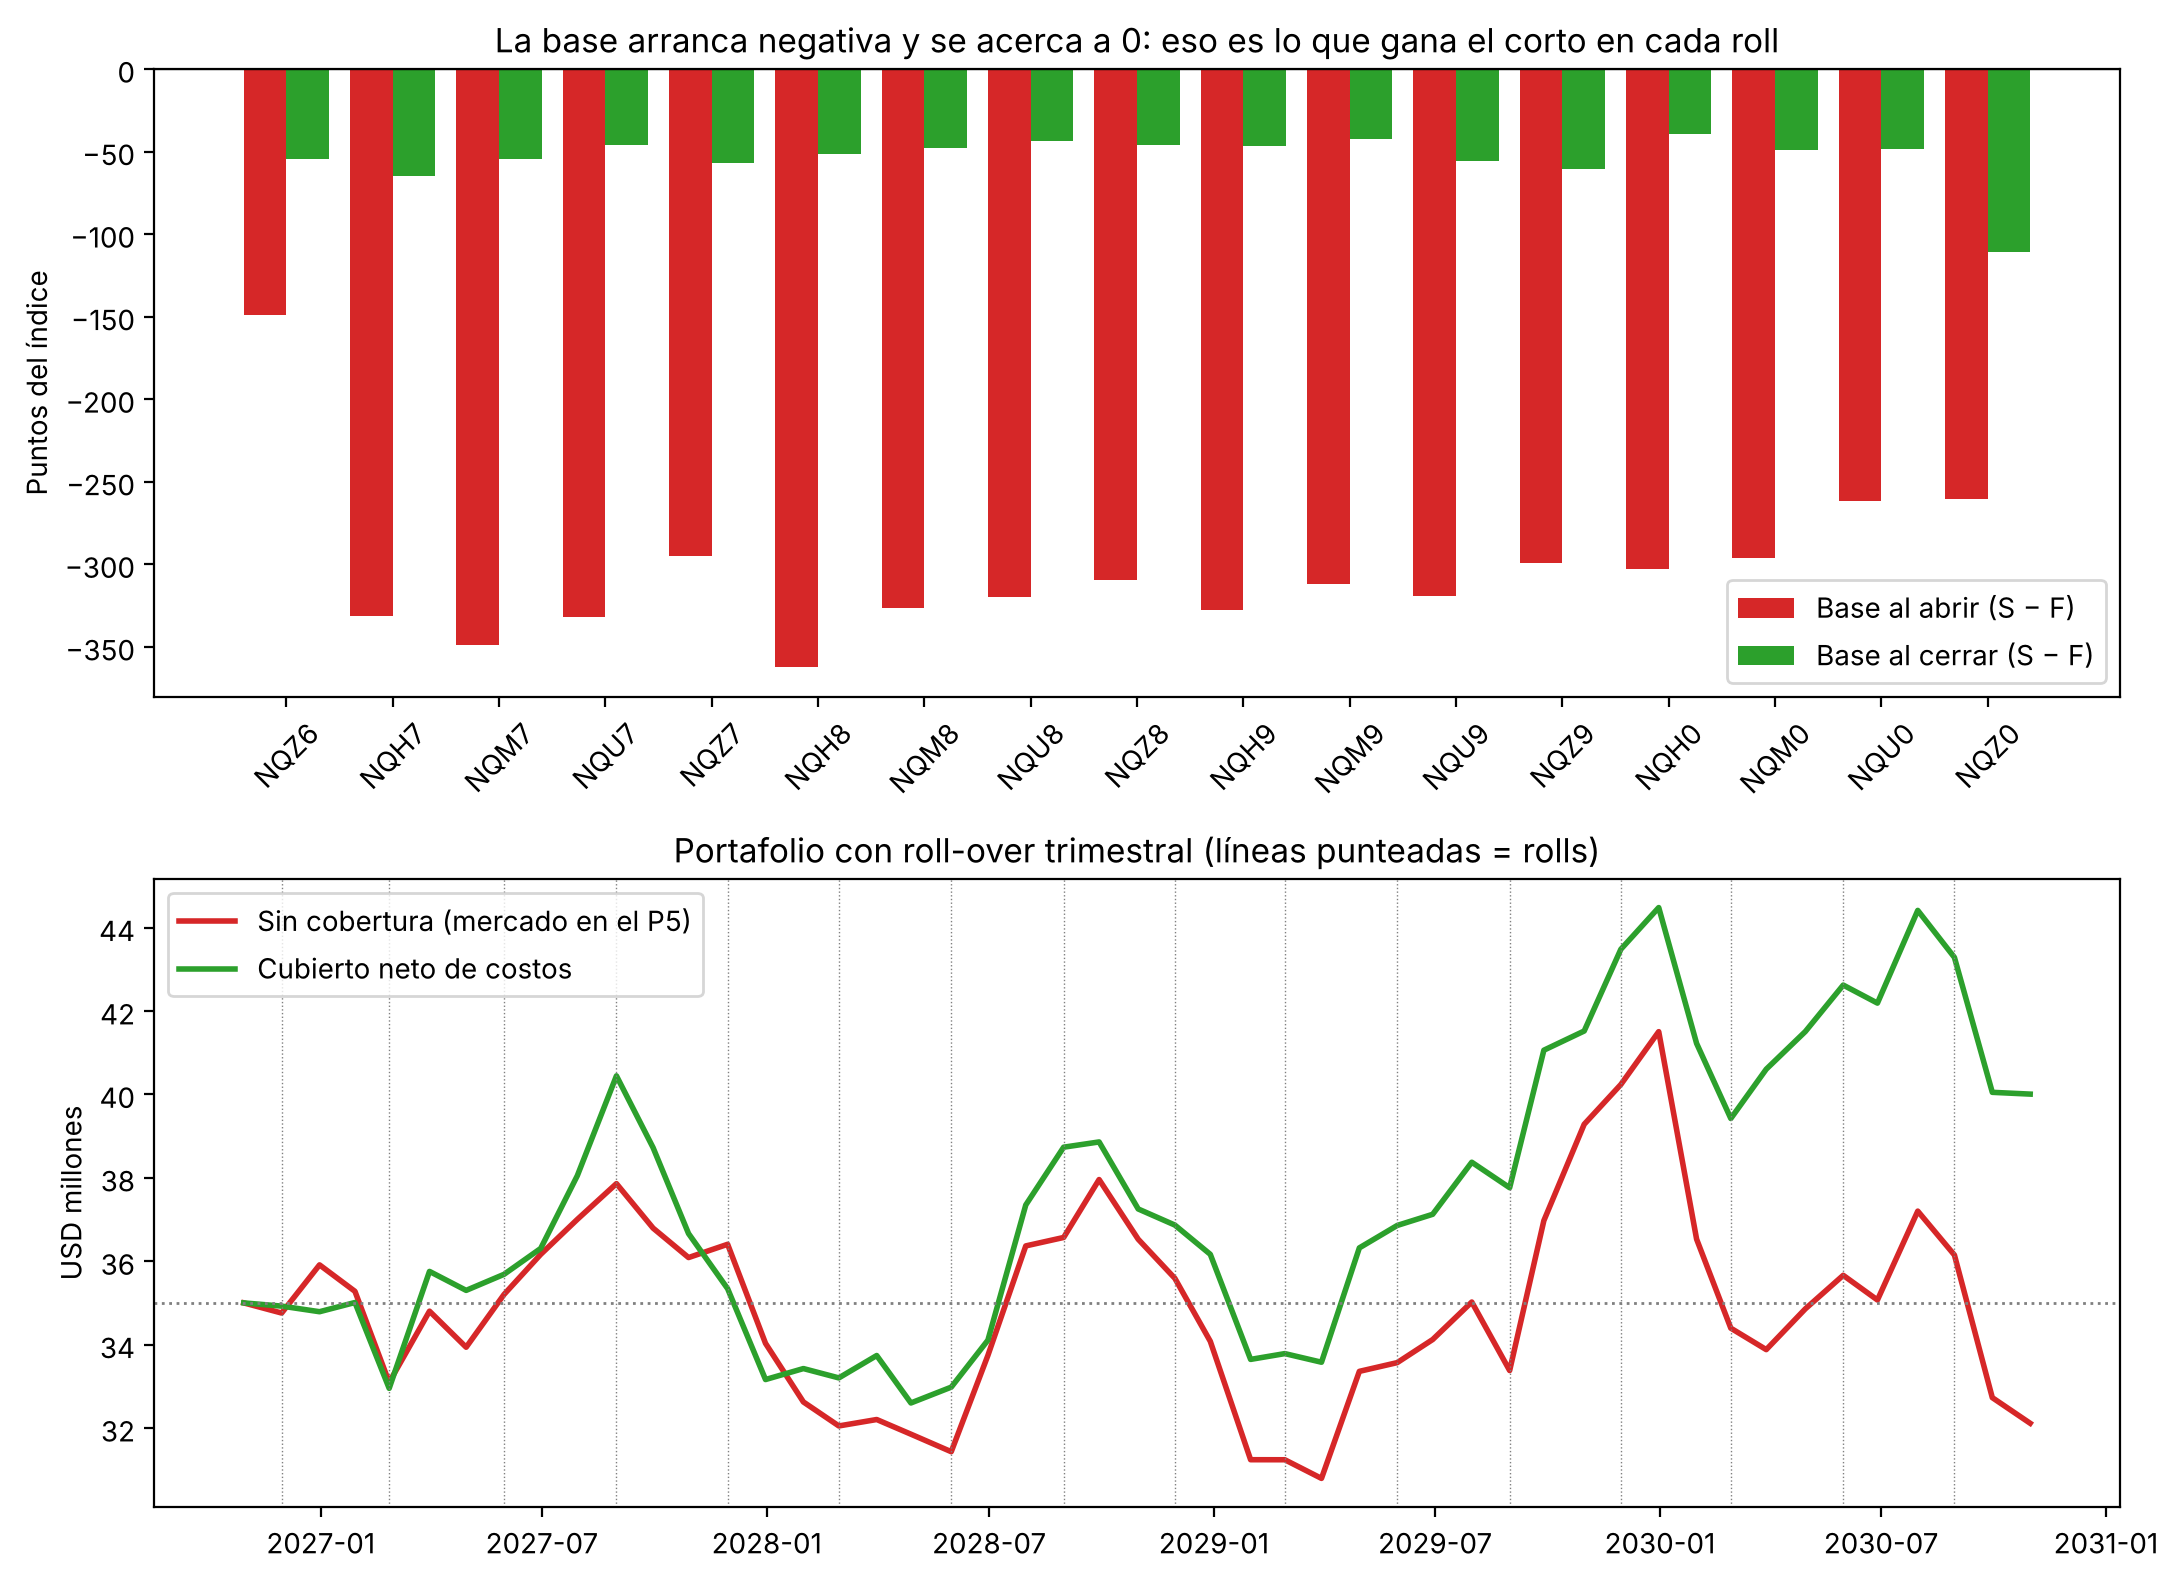

In [26]:
# 9.5 Gráfico: base al abrir y al cerrar cada contrato (escenario principal) y valor del portafolio
fig, ax = plt.subplots(2, 1, figsize=(11, 8))
x = np.arange(len(rolls))
ax[0].bar(x - 0.2, rolls["Base apertura"], width=0.4, color="tab:red", label="Base al abrir (S − F)")
ax[0].bar(x + 0.2, rolls["Base cierre"], width=0.4, color="tab:green", label="Base al cerrar (S − F)")
ax[0].set_xticks(x); ax[0].set_xticklabels(rolls.index, rotation=45)
ax[0].axhline(0, color="black", lw=0.8); ax[0].set_ylabel("Puntos del índice"); ax[0].legend()
ax[0].set_title("La base arranca negativa y se acerca a 0: eso es lo que gana el corto en cada roll")
ax[1].plot(fechas, V_sin[:, k5] / 1e6, color="tab:red", lw=2, label="Sin cobertura (mercado en el P5)")
ax[1].plot(fechas, V_cub_neto[:, k5] / 1e6, color="tab:green", lw=2, label="Cubierto neto de costos")
for f_ in pd.to_datetime(rolls["Cierre"].iloc[:-1]):
    ax[1].axvline(f_, color="gray", lw=0.5, ls=":")
ax[1].axhline(Vp / 1e6, color="gray", ls=":", lw=1)
ax[1].set_ylabel("USD millones"); ax[1].legend(); ax[1].set_title("Portafolio con roll-over trimestral (líneas punteadas = rolls)")
plt.tight_layout(); fig.savefig(RAIZ / "outputs" / "figures" / "rollover_base_v2.png", dpi=150); plt.show()

Lectura del Punto 9:

- Lógica del roll: se usaron 17 contratos (NQZ6 → NQZ0) con 16 renovaciones. El NQZ6 solo dura un mes (vence el 18/12/2026) y el NQZ0 dos meses, porque la cobertura termina en oct-2030. La suma del P&G realizado de los 17 contratos (+USD 7,90 M) es igual a la suma de las liquidaciones mensuales del Punto 8. El roll no crea plata nueva, solo cierra lo que ya se liquidó mes a mes y abre el contrato siguiente.
- De dónde sale la ganancia del corto en el escenario principal (mercado en el P5):
    - Spot, +USD 5,10 M: es la cobertura en sí. El índice bajó y el corto lo compensó.
    - Base, +USD 2,80 M: es el roll yield. Cada contrato se abre con una base de unos −300 puntos (el futuro está por encima del índice) y se cierra con unos −50, porque se acerca al vencimiento. En cada roll el contrato nuevo se vende en promedio 262 puntos por encima del que se cierra, unos USD 173 mil para los 33 contratos.
- En las 10.000 trayectorias el roll yield da en promedio USD 3,46 M (entre 2,4 y 4,8 M en el 90 % de los casos), más o menos 2,4 % anual sobre los USD 35 M. Esto se gana suba o baje el mercado, porque viene del costo de llevar y no de la dirección del índice. Por eso el portafolio cubierto termina cerca de la tasa libre de riesgo y no en cero.
- Riesgo de base: ese roll yield no está garantizado. Depende de c = r − q, que se mueve con las tasas de corto plazo y los dividendos del índice. Si c baja un punto (2,90 %), el roll yield promedio cae a USD 2,57 M; si sube un punto, sube a USD 4,35 M. Cada punto de c vale unos USD 0,9 M en 4 años. Además, como el futuro es sobre el índice y no sobre nuestras acciones, sigue estando el riesgo propio (R² = 0,33).
- Costos: 1.122 lados (33 contratos × 2 × 17) × USD 7,247 = USD 8.131 en 4 años, casi nada (0,006 % anual). El costo de verdad de la cobertura no son las comisiones, es la liquidez para los llamados al margen (Punto 8.7).
- Efecto sobre la rentabilidad en el escenario principal: sin cobertura el portafolio pierde 2,13 % anual (termina en USD 32,1 M); cubierto, neto de costos, gana 3,40 % anual (USD 40,0 M). La volatilidad mensual baja de 4,71 % a 4,24 % y el peor mes pasa de −12,0 % a −7,5 %. No baja más porque el 67 % del riesgo es propio de las acciones y eso el futuro no lo toca.


## Punto 10 – Valor esperado de la cobertura trimestral y tasa libre de riesgo (R12 – 7 %)

### 10.1 Tasa libre de riesgo

Usamos ^TNX al 30/10/2026 = 4,929 % anual (Yahoo Finance, `data/raw/tnx.csv`). ^TNX cotiza en puntos porcentuales, así que 4,929 = 4,929 %.

Una aclaración sobre el enunciado: ahí se describe ^TNX como el "CBOE Interest Rate 1 to 3 Year Treasury Index", pero en realidad ^TNX es el rendimiento del bono del Tesoro a 10 años. Aun así lo preferimos frente a una tasa muy corta como ^IRX (T-Bill a 13 semanas), por tres razones:

1. El horizonte de inversión es de 4 años, y una tasa de más plazo refleja mejor el costo de oportunidad de la plata en ese tiempo.
2. Es la referencia que pidió el profe y la más usada como libre de riesgo en valoración.
3. Es la misma r_f que está detrás del ERP de Damodaran que usamos en la simulación (Punto 8), así que todo queda coherente.

Para pasarla a mensual y trimestral usamos tasa efectiva (compuesta), porque el portafolio se va acumulando mes a mes:

$$r_{f,m} = (1 + r_f)^{1/12} - 1 \qquad r_{f,q} = (1 + r_f)^{1/4} - 1$$

La alternativa sería la nominal ($r_f/12$, $r_f/4$), pero al capitalizarla da una tasa anual más alta que la observada y sobrestima lo que paga el activo libre de riesgo.

In [27]:
# 10.1 Tasa libre de riesgo: efectiva vs. nominal (rf viene del Punto 8: ^TNX / 100)
rf_mes  = (1 + rf) ** (1 / 12) - 1                  # efectiva mensual
rf_trim = (1 + rf) ** (1 / 4) - 1                   # efectiva trimestral
tasas = pd.DataFrame({
    "Efectiva (compuesta)": [rf_mes, rf_trim, (1 + rf_mes) ** 12 - 1],
    "Nominal (simple)":     [rf / 12, rf / 4, (1 + rf / 12) ** 12 - 1],
}, index=["Mensual", "Trimestral", "Anual que resulta al capitalizar"])
print(f"^TNX al 30/10/2026 = {rf * 100:.3f} -> r_f = {rf:.5f} | V0 a r_f en 4 años = {Vp * (1 + rf) ** 4:,.0f} USD")
tasas.style.format("{:.4%}")

^TNX al 30/10/2026 = 4.929 -> r_f = 0.04929 | V0 a r_f en 4 años = 42,427,767 USD


,Efectiva (compuesta),Nominal (simple)
Mensual,0.4018%,0.4107%
Trimestral,1.2101%,1.2322%
Anual que resulta al capitalizar,4.9290%,5.0419%


### 10.2 Valor esperado de la cobertura, trimestre a trimestre

Con las 10.000 trayectorias del Punto 8 (y los costos del Punto 9) calculamos, al cierre de cada trimestre T1–T16:

- $E[V_{sin}]$ y $E[V_{cub}]$: valor esperado del portafolio sin cobertura y cubierto (neto de costos).
- El valor esperado de la cobertura en el trimestre: lo que en promedio gana o pierde la posición en futuros en esos 3 meses, menos los costos.
- Ese flujo traído a hoy con la tasa libre de riesgo trimestral: $VP = \sum_q \dfrac{E[\text{cobertura}_q]}{(1 + r_{f,q})^q}$.
- La referencia libre de riesgo: $V_0\,(1 + r_{f,q})^q$.

In [28]:
# 10.2 Valor esperado trimestral (meses 0, 3, …, 48)
idx_q = np.arange(0, n_mes + 1, 3)
nq    = np.arange(len(idx_q))                                   # trimestre 0..16
cob   = PG_acum - costos_acum[:, None]                          # resultado acumulado de la cobertura (futuros − costos)
ve = pd.DataFrame({
    "Fecha": fechas[idx_q].date,
    "E[V] sin cobertura": V_sin[idx_q].mean(axis=1),
    "E[V] cubierto": V_cub_neto[idx_q].mean(axis=1),
    "V libre de riesgo": Vp * (1 + rf_trim) ** nq,
    "Mediana cubierto": np.median(V_cub_neto[idx_q], axis=1),
    "E[cobertura acumulada]": cob[idx_q].mean(axis=1),
}, index=[f"T{k}" for k in nq])
ve["E[cobertura del trimestre]"] = ve["E[cobertura acumulada]"].diff()            # flujo esperado de cada trimestre
ve["VP a r_f"] = ve["E[cobertura del trimestre]"] / (1 + rf_trim) ** nq            # descontado con r_f trimestral
ve.to_csv(PROC / "valor_esperado_trimestral_v2.csv")
print(f"VP de la cobertura (16 trimestres, descontado a r_f) = {ve['VP a r_f'].sum():+,.0f} USD")
ve.style.format({c_: "{:,.0f}" for c_ in ve.columns if c_ != "Fecha"} |
                {c_: "{:+,.0f}" for c_ in ["E[cobertura acumulada]", "E[cobertura del trimestre]", "VP a r_f"]}, na_rep="—")

VP de la cobertura (16 trimestres, descontado a r_f) = -3,678,644 USD


,Fecha,E[V] sin cobertura,E[V] cubierto,V libre de riesgo,Mediana cubierto,E[cobertura acumulada],E[cobertura del trimestre],VP a r_f
T0,2026-10-30,"35,000,000","34,999,761","35,000,000","34,999,761",-239,—,—
T1,2027-01-29,"35,648,673","35,450,886","35,423,537","35,358,210","-197,787","-197,548","-195,186"
T2,2027-04-30,"36,360,701","35,915,266","35,852,200","35,747,220","-445,435","-247,648","-241,761"
T3,2027-07-30,"37,009,488","36,360,429","36,286,050","36,050,852","-649,059","-203,624","-196,407"
T4,2027-10-29,"37,731,415","36,855,014","36,725,150","36,483,004","-876,401","-227,342","-216,663"
T5,2028-01-31,"38,488,993","37,380,369","37,169,564","36,864,313","-1,108,624","-232,223","-218,669"
T6,2028-04-28,"39,278,369","37,891,122","37,619,355","37,303,547","-1,387,246","-278,622","-259,222"
T7,2028-07-31,"40,081,790","38,449,681","38,074,589","37,754,883","-1,632,109","-244,863","-225,090"
T8,2028-10-31,"40,828,246","38,964,403","38,535,333","38,146,750","-1,863,843","-231,734","-210,474"
T9,2029-01-31,"41,570,221","39,462,320","39,001,651","38,489,161","-2,107,901","-244,058","-219,017"


### 10.3 Sin cobertura vs. cubierto a 4 años

In [29]:
# 10.3 Resumen a 4 años: ¿la cobertura reduce el riesgo, la rentabilidad o ambos?
V_rf = Vp * (1 + rf) ** 4
def resumen(V):
    f = V[-1]
    return {"E[valor final] (USD)": f.mean(), "E[rentabilidad anual]": (f.mean() / Vp) ** (1 / 4) - 1,
            "Mediana del valor final (USD)": np.median(f), "σ del valor final (USD)": f.std(),
            "P5 del valor final (USD)": np.quantile(f, .05), "P95 del valor final (USD)": np.quantile(f, .95),
            "Prob. de terminar por debajo de USD 35 M": (f < Vp).mean(),
            "Prob. de no superar la tasa libre de riesgo": (f < V_rf).mean()}

res10 = pd.DataFrame({"Sin cobertura": resumen(V_sin), "Cubierto (neto de costos)": resumen(V_cub_neto)})
res10.loc["E[valor final] (USD)", "Libre de riesgo"] = V_rf
res10.loc["E[rentabilidad anual]", "Libre de riesgo"] = rf
res10.to_csv(PROC / "resumen_valor_esperado_v2.csv")
res10.style.format(lambda x: "—" if pd.isna(x) else (f"{x:,.0f}" if abs(x) > 10 else f"{x:.2%}"))

,Sin cobertura,Cubierto (neto de costos),Libre de riesgo
E[valor final] (USD),"47,694,996","43,601,406","42,427,767"
E[rentabilidad anual],8.04%,5.65%,4.93%
Mediana del valor final (USD),"44,943,022","41,590,393",—
σ del valor final (USD),"17,445,249","14,566,388",—
P5 del valor final (USD),"24,909,314","23,654,306",—
P95 del valor final (USD),"80,370,377","70,086,680",—
Prob. de terminar por debajo de USD 35 M,24.44%,29.22%,—
Prob. de no superar la tasa libre de riesgo,43.80%,52.44%,—


Un promedio de todo junto esconde para qué sirve la cobertura. Por eso partimos las 10.000 trayectorias en cinco grupos según cómo le fue al Nasdaq en los 4 años (quintiles del índice final) y comparamos el valor esperado sin cobertura y cubierto en cada grupo.

In [30]:
# 10.4 Valor esperado según cómo le fue al mercado (quintiles del ^NDX a 4 años)
quint = pd.qcut(S_arr[-1], 5, labels=["Q1 (mercado muy malo)", "Q2", "Q3", "Q4", "Q5 (mercado muy bueno)"])
por_q = pd.DataFrame({"^NDX var. 4 años (prom.)": S_arr[-1] / S0 - 1, "E[V] sin cobertura": V_sin[-1],
                      "E[V] cubierto": V_cub_neto[-1]}).groupby(quint, observed=True).mean()
por_q["Diferencia (cubierto − sin)"] = por_q["E[V] cubierto"] - por_q["E[V] sin cobertura"]
por_q.to_csv(PROC / "valor_esperado_por_quintil_v2.csv")
por_q.style.format({"^NDX var. 4 años (prom.)": "{:+.1%}", "E[V] sin cobertura": "{:,.0f}",
                    "E[V] cubierto": "{:,.0f}", "Diferencia (cubierto − sin)": "{:+,.0f}"})

,^NDX var. 4 años (prom.),E[V] sin cobertura,E[V] cubierto,Diferencia (cubierto − sin)
Q1 (mercado muy malo),-21.7%,"35,069,763","41,799,746","+6,729,983"
Q2,+7.2%,"42,827,977","44,550,201","+1,722,224"
Q3,+30.8%,"46,549,249","44,144,547","-2,404,702"
Q4,+59.5%,"51,703,830","44,281,028","-7,422,802"
Q5 (mercado muy bueno),+125.5%,"62,324,160","43,231,508","-19,092,652"


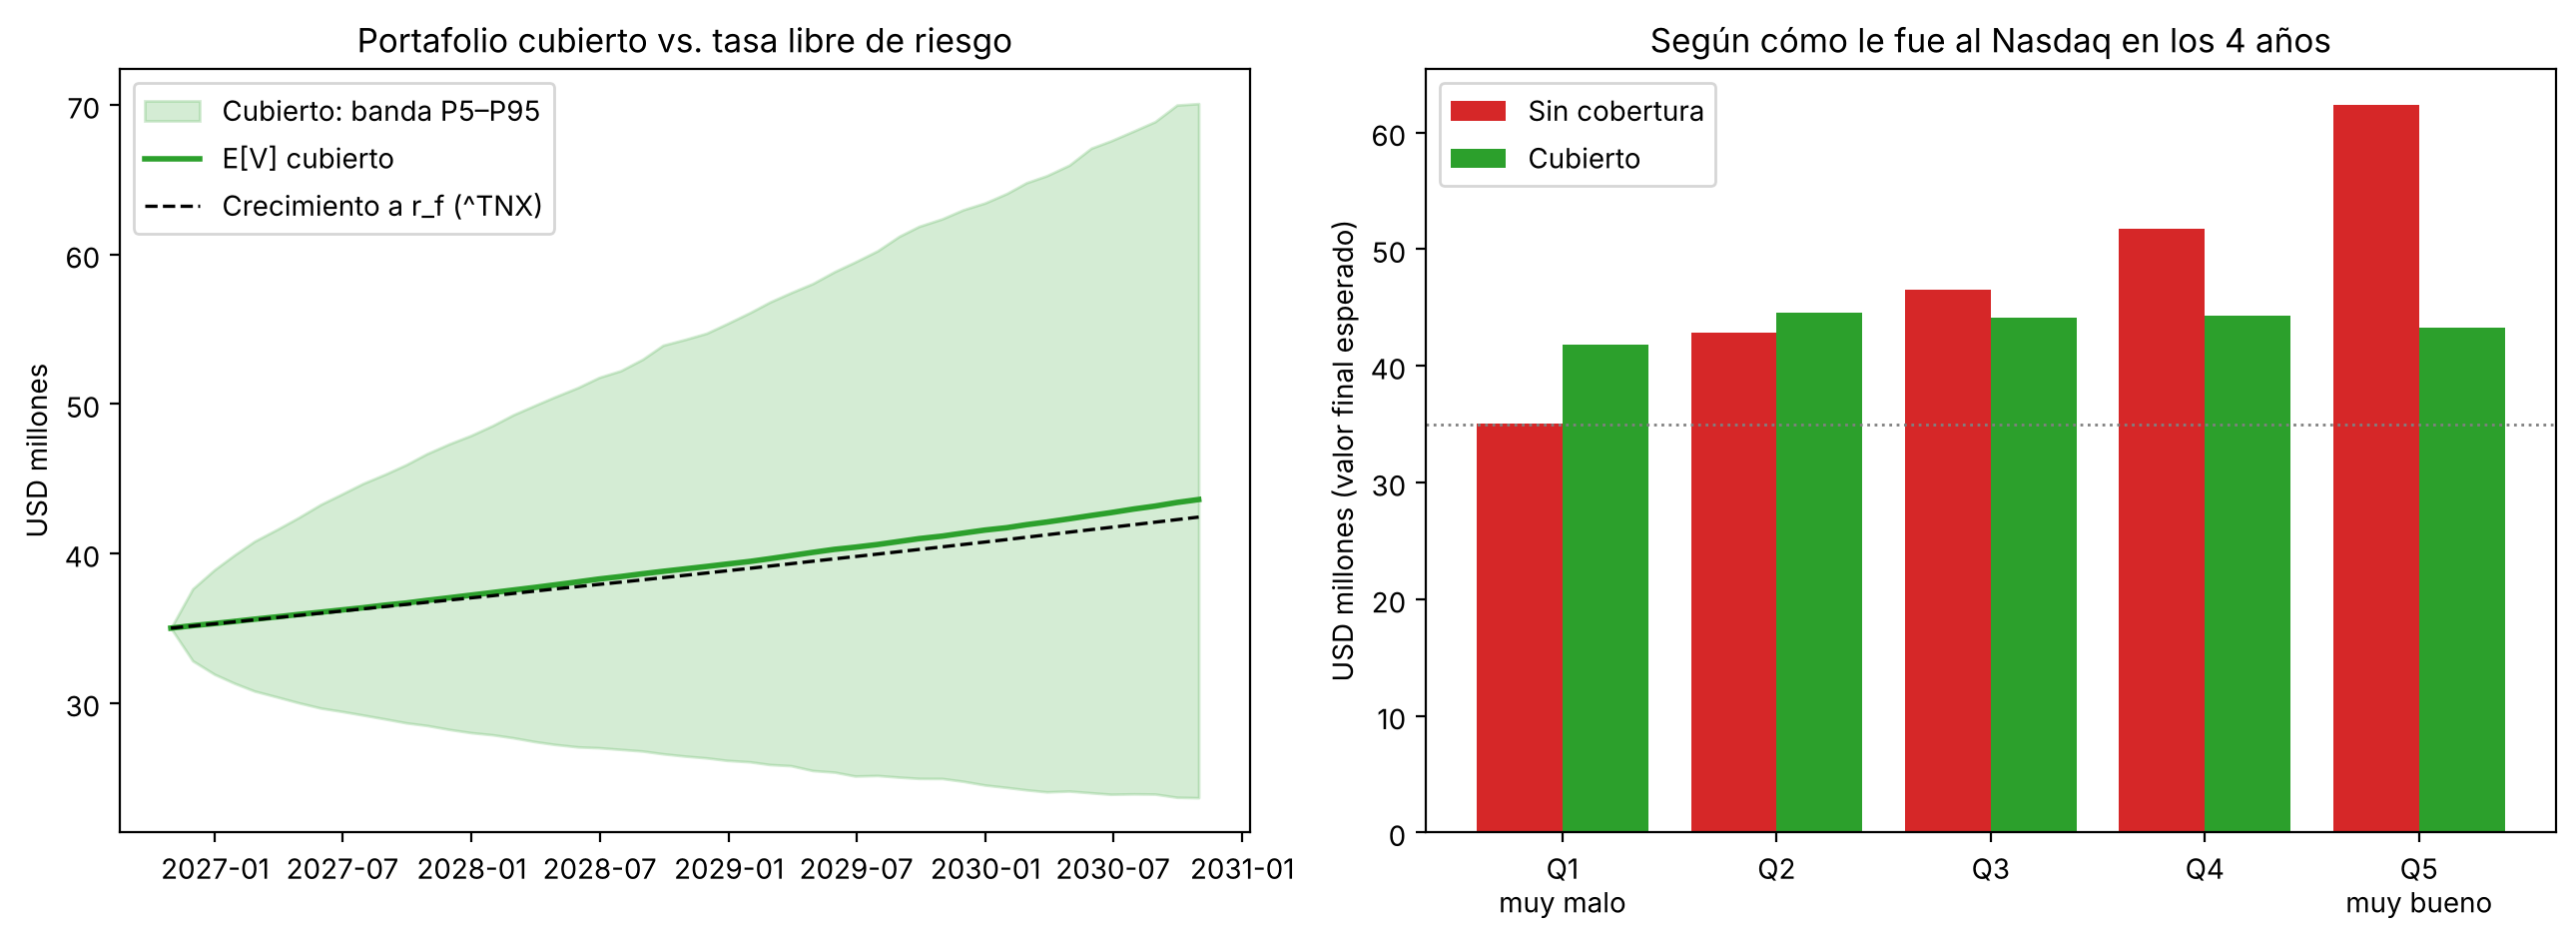

In [31]:
# 10.5 Gráfico: valor esperado del cubierto vs. r_f, y efecto de la cobertura según el mercado
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].fill_between(fechas, np.quantile(V_cub_neto, .05, axis=1) / 1e6, np.quantile(V_cub_neto, .95, axis=1) / 1e6,
                   color="tab:green", alpha=.2, label="Cubierto: banda P5–P95")
ax[0].plot(fechas, V_cub_neto.mean(axis=1) / 1e6, color="tab:green", lw=2, label="E[V] cubierto")
ax[0].plot(fechas[idx_q], ve["V libre de riesgo"] / 1e6, "k--", lw=1.2, label="Crecimiento a r_f (^TNX)")
ax[0].set_ylabel("USD millones"); ax[0].legend(loc="upper left"); ax[0].set_title("Portafolio cubierto vs. tasa libre de riesgo")
x = np.arange(len(por_q))
ax[1].bar(x - .2, por_q["E[V] sin cobertura"] / 1e6, width=.4, color="tab:red", label="Sin cobertura")
ax[1].bar(x + .2, por_q["E[V] cubierto"] / 1e6, width=.4, color="tab:green", label="Cubierto")
ax[1].axhline(Vp / 1e6, color="gray", ls=":", lw=1)
ax[1].set_xticks(x); ax[1].set_xticklabels(["Q1\nmuy malo", "Q2", "Q3", "Q4", "Q5\nmuy bueno"])
ax[1].set_ylabel("USD millones (valor final esperado)"); ax[1].legend()
ax[1].set_title("Según cómo le fue al Nasdaq en los 4 años")
plt.tight_layout(); fig.savefig(RAIZ / "outputs" / "figures" / "valor_esperado_cobertura_v2.png", dpi=150); plt.show()

Lectura del Punto 10:

- Tasa libre de riesgo: la efectiva mensual es 0,4018 % y la trimestral 1,2101 %. Si usáramos las nominales (0,4108 % y 1,2323 %) y las capitalizáramos, la tasa anual daría 5,04 % en vez del 4,929 % observado. Por eso usamos las efectivas.
- Valor esperado de la cobertura trimestral: en cada trimestre la posición en futuros pierde en promedio entre USD 0,20 M y 0,32 M (neto de costos). Traídos a hoy con la r_f trimestral, los 16 trimestres suman −USD 3,68 M. Ese es el precio esperado del seguro: con μ = r_f + ERP el mercado sube en promedio, y el corto renuncia a esa prima sobre la parte que cubre. Con la calibración neutral al riesgo (8.8) este valor esperado sería prácticamente cero, porque el futuro está bien valorado.
- Valor esperado a 4 años: sin cobertura USD 47,7 M (8,0 % anual), cubierto USD 43,6 M (5,6 % anual) y a la tasa libre de riesgo USD 42,4 M (4,93 %). El cubierto queda cerca de la r_f, como dice la teoría: al quitar el riesgo de mercado, lo que queda se parece a un activo sin riesgo de mercado. El promedio queda un poco arriba de la r_f porque el riesgo propio de las acciones abre la distribución hacia arriba; la mediana del cubierto (USD 41,6 M) sí queda un poco por debajo.
- Para qué sirve, en la tabla por quintiles: cuando al Nasdaq le va muy mal (Q1, −22 % en promedio), sin cobertura terminamos en USD 35,1 M y cubiertos en USD 41,8 M, unos 6,7 M más. Cuando le va muy bien (Q5, +126 %), sin cobertura llegamos a USD 62,3 M y cubiertos a USD 43,2 M. Con cobertura, el valor final queda entre USD 41,8 y 44,6 M en los cinco grupos: ya casi no depende de lo que haga el mercado.
- ¿Reduce el riesgo, la rentabilidad o ambos? Ambos:
    - La rentabilidad esperada baja de 8,0 % a 5,6 % anual (−USD 4,1 M). Es la prima de mercado que se entrega a cambio de la protección.
    - El riesgo de mercado prácticamente desaparece (quintiles). Pero la dispersión total del valor final solo baja un 17 % (σ de USD 17,4 M a 14,6 M), y la probabilidad de terminar por debajo de USD 35 M no mejora (24 % sin cobertura vs. 29 % cubierto). La razón es el R² de 0,33: dos terceras partes del riesgo son propias de CSCO, ADI y AMGN, y eso el futuro no lo toca. Encima, el cubierto ya no tiene la prima de mercado que en promedio empujaba el valor hacia arriba.
- Conclusión para el gerente: la cobertura con futuros del índice hace bien lo que promete, que es proteger frente a una caída del mercado (Puntos 8 y 10.4). No convierte el portafolio en un bono, porque con este portafolio GMV (mucho AMGN, β = 0,54) la mayor parte del riesgo no es de mercado. Además exige caja para los llamados al margen (en promedio USD 9,1 M repuestos en 4 años, Punto 8.7).


## Punto 11 – Rendimiento y valor esperado mensual: tres enfoques y dividendos (R13 – 6 %)

Mes a mes, durante los 48 meses, miramos cuánto esperamos ganar y cuánto valdría la cartera desde tres miradas:

| Enfoque | ¿Qué responde? | Cómo lo calculamos |
|---|---|---|
| (a) Sin cobertura | ¿Cuánto rinde la cartera si no nos cubrimos? | Promedio de las 10.000 trayectorias del Punto 8 |
| (b) Cubierto con futuros | ¿Cuánto rinde con los 33 NQ cortos? | Acciones + futuros − costos, promediado en las 10.000 (Punto 9) |
| (c) Ajustado por VaR | ¿Cuánto valdría si nos toca un mes malo? | Valor esperado del mes anterior × (1 − VaR mensual) |

Sobre el enfoque (c), que es construcción nuestra (igual que la hoja "cobertura corta trimestral" del Excel de ejemplo, que castiga el valor de cartera con el VaR): usamos los VaR mensuales del Punto 4. Sin cobertura: 6,87 % al 95 % y 10,08 % al 99 %. Con cobertura ideal del riesgo de mercado: 5,41 % y 8,08 %. Lo chequeamos contra el VaR del primer mes que sale de la simulación.

Dividendos: las tres pagan (Punto 0). Para cada una sumamos lo que pagó en los últimos 12 meses (31/10/2025 – 30/10/2026) y lo dividimos por su precio al 30/10/2026. El del portafolio es el promedio con los pesos del GMV. Como es anual, lo pasamos a mensual con tasa efectiva: $q_m = (1+q)^{1/12} - 1$.

¿Cómo no contarlos dos veces? Las betas y el VaR salen del Adj Close, o sea, de retornos totales (precio + dividendos), y en la simulación el mercado también rinde r_f + ERP en total. Entonces el valor simulado del portafolio ya trae los dividendos adentro, como si se reinvirtieran. No los sumamos otra vez: los separamos para ver cuánto pesan.

$$r^{total}_{t} \approx r^{precio}_{t} + q_m \qquad D_t = E[V_{t-1}] \cdot q_m$$

Y un punto clave: cubrirse con futuros no quita los dividendos. Seguimos siendo dueños de las acciones y los seguimos cobrando.

In [32]:
# 11.1 Dividend yield de cada acción y del portafolio (últimos 12 meses al 30/10/2026)
divs    = pd.read_csv(PROC / "divs_v2.csv", index_col=0, parse_dates=True)
pesos_s = pd.Series(w, index=ACCIONES)                               # pesos del GMV
div_12m = divs.loc["2025-10-31":"2026-10-30", ACCIONES].sum()        # USD por acción pagados en 12 meses
precio  = close.loc["2026-10-30", ACCIONES]                          # precio al 30/10/2026
q_acc   = div_12m / precio                                           # dividend yield anual de cada una
q_port  = (pesos_s * q_acc).sum()                                    # dividend yield del portafolio
q_port_m = (1 + q_port) ** (1 / 12) - 1                              # efectiva mensual

tabla_div = pd.DataFrame({"Peso GMV": pesos_s, "Dividendos 12 m (USD/acción)": div_12m, "Precio 30/10/2026": precio,
                          "Dividend yield anual": q_acc, "Aporte al portafolio": pesos_s * q_acc})
tabla_div.to_csv(PROC / "dividendos_v2.csv")
print(f"Dividend yield del portafolio: q = {q_port:.4%} anual -> q_m = {q_port_m:.4%} mensual "
      f"(≈ USD {Vp * q_port_m:,.0f} el primer mes)")
tabla_div.style.format({"Peso GMV": "{:.2%}", "Dividendos 12 m (USD/acción)": "{:.2f}", "Precio 30/10/2026": "{:,.2f}",
                        "Dividend yield anual": "{:.2%}", "Aporte al portafolio": "{:.2%}"})

Dividend yield del portafolio: q = 1.7227% anual -> q_m = 0.1424% mensual (≈ USD 49,852 el primer mes)


,Peso GMV,Dividendos 12 m (USD/acción),Precio 30/10/2026,Dividend yield anual,Aporte al portafolio
CSCO,36.71%,1.67,104.51,1.60%,0.59%
ADI,19.37%,4.29,417.11,1.03%,0.20%
AMGN,43.92%,9.94,466.01,2.13%,0.94%


In [33]:
# 11.2 Rendimiento y valor esperado mensual bajo los tres enfoques (48 meses)
var95_sin = var_cs.loc["VaR 95%", "Sin cobertura (%)"]; var99_sin = var_cs.loc["VaR 99%", "Sin cobertura (%)"]
var95_cub = var_cs.loc["VaR 95%", "Cubierto (%)"];      var99_cub = var_cs.loc["VaR 99%", "Cubierto (%)"]

EV_sin, EV_cub = V_sin.mean(axis=1), V_cub_neto.mean(axis=1)       # E[V_t], meses 0..48 (retorno total)
r_sin = EV_sin[1:] / EV_sin[:-1] - 1                                # rendimiento esperado mensual (total)
r_cub = EV_cub[1:] / EV_cub[:-1] - 1
D_sin = EV_sin[:-1] * q_port_m                                      # dividendos esperados del mes (USD)
D_cub = EV_cub[:-1] * q_port_m

enf = pd.DataFrame({
    "Trimestre": [f"T{(t - 1) // 3 + 1}" for t in range(1, n_mes + 1)],
    "(a) r total": r_sin, "(a) r precio": r_sin - q_port_m, "(a) E[V]": EV_sin[1:], "(a) dividendos del mes": D_sin,
    "(b) r total": r_cub, "(b) r precio": r_cub - q_port_m, "(b) E[V]": EV_cub[1:], "(b) dividendos del mes": D_cub,
    "(c) V si VaR 95 % sin": EV_sin[:-1] * (1 - var95_sin), "(c) V si VaR 99 % sin": EV_sin[:-1] * (1 - var99_sin),
    "(c) V si VaR 95 % cub": EV_cub[:-1] * (1 - var95_cub), "(c) V si VaR 99 % cub": EV_cub[:-1] * (1 - var99_cub),
}, index=pd.Index(range(1, n_mes + 1), name="Mes"))
enf.insert(0, "Fecha", fechas[1:].date)
enf.to_csv(PROC / "tres_enfoques_mensual_v2.csv")

pct = [c_ for c_ in enf.columns if " r " in f" {c_} "]
enf.style.format({c_: "{:+.3%}" for c_ in pct} | {c_: "{:,.0f}" for c_ in enf.columns if c_ not in pct + ["Fecha", "Trimestre"]})

,Fecha,Trimestre,(a) r total,(a) r precio,(a) E[V],(a) dividendos del mes,(b) r total,(b) r precio,(b) E[V],(b) dividendos del mes,(c) V si VaR 95 % sin,(c) V si VaR 99 % sin,(c) V si VaR 95 % cub,(c) V si VaR 99 % cub
Mes,,,,,,,,,,,,,,
1,2026-11-30,T1,+0.687%,+0.545%,"35,240,446","49,852",+0.471%,+0.329%,"35,164,654","49,852","32,596,129","31,473,608","33,104,694","32,170,441"
2,2026-12-31,T1,+0.568%,+0.425%,"35,440,450","50,195",+0.406%,+0.263%,"35,307,337","50,087","32,820,061","31,689,828","33,260,660","32,322,005"
3,2027-01-29,T1,+0.588%,+0.445%,"35,648,673","50,480",+0.407%,+0.264%,"35,450,886","50,290","33,006,328","31,869,681","33,395,617","32,453,153"
4,2027-02-26,T2,+0.705%,+0.563%,"35,900,120","50,776",+0.410%,+0.268%,"35,596,342","50,494","33,200,250","32,056,925","33,531,393","32,585,098"
5,2027-03-31,T2,+0.693%,+0.551%,"36,148,968","51,134",+0.451%,+0.309%,"35,756,958","50,702","33,434,427","32,283,037","33,668,974","32,718,796"
6,2027-04-30,T2,+0.586%,+0.443%,"36,360,701","51,489",+0.443%,+0.300%,"35,915,266","50,930","33,666,183","32,506,812","33,820,893","32,866,428"
7,2027-05-31,T3,+0.590%,+0.447%,"36,575,094","51,790",+0.413%,+0.270%,"36,063,483","51,156","33,863,374","32,697,213","33,970,630","33,011,938"
8,2027-06-30,T3,+0.608%,+0.466%,"36,797,456","52,096",+0.416%,+0.274%,"36,213,507","51,367","34,063,042","32,890,005","34,110,821","33,148,174"
9,2027-07-30,T3,+0.576%,+0.434%,"37,009,488","52,412",+0.406%,+0.263%,"36,360,429","51,581","34,270,132","33,089,963","34,252,722","33,286,070"


In [34]:
# 11.3 Resumen de los tres enfoques
anual = lambda r: (1 + r) ** 12 - 1
var_sim_95 = lambda V: -np.quantile(V[1] / V[0] - 1, .05)           # VaR 95 % del primer mes, según la simulación
res11 = pd.DataFrame({
    "(a) Sin cobertura": {
        "Rend. esperado mensual (total)": r_sin.mean(), "  · por precio": r_sin.mean() - q_port_m, "  · por dividendos": q_port_m,
        "Rend. anual equivalente (total)": anual(r_sin.mean()),
        "Valor esperado a 4 años (USD)": EV_sin[-1], "  · de eso, dividendos cobrados (USD)": D_sin.sum(),
        "VaR 95 % del mes (Punto 4)": var95_sin, "VaR 95 % del 1.er mes (simulación)": var_sim_95(V_sin)},
    "(b) Cubierto con futuros": {
        "Rend. esperado mensual (total)": r_cub.mean(), "  · por precio": r_cub.mean() - q_port_m, "  · por dividendos": q_port_m,
        "Rend. anual equivalente (total)": anual(r_cub.mean()),
        "Valor esperado a 4 años (USD)": EV_cub[-1], "  · de eso, dividendos cobrados (USD)": D_cub.sum(),
        "VaR 95 % del mes (Punto 4)": var95_cub, "VaR 95 % del 1.er mes (simulación)": var_sim_95(V_cub_neto)},
    "(c) Ajustado por VaR – sin cobertura": {
        "Pérdida en un mes malo, VaR 95 % (USD, 1.er mes)": Vp * var95_sin, "Pérdida en un mes malo, VaR 99 % (USD, 1.er mes)": Vp * var99_sin,
        "Valor a 4 años si el último mes es malo (VaR 95 %)": enf["(c) V si VaR 95 % sin"].iloc[-1]},
    "(c) Ajustado por VaR – cubierto": {
        "Pérdida en un mes malo, VaR 95 % (USD, 1.er mes)": Vp * var95_cub, "Pérdida en un mes malo, VaR 99 % (USD, 1.er mes)": Vp * var99_cub,
        "Valor a 4 años si el último mes es malo (VaR 95 %)": enf["(c) V si VaR 95 % cub"].iloc[-1]},
})
res11.to_csv(PROC / "resumen_tres_enfoques_v2.csv")
res11.style.format(lambda x: "—" if pd.isna(x) else (f"{x:,.0f}" if abs(x) > 10 else f"{x:+.3%}"))

,(a) Sin cobertura,(b) Cubierto con futuros,(c) Ajustado por VaR – sin cobertura,(c) Ajustado por VaR – cubierto
Rend. esperado mensual (total),+0.647%,+0.459%,—,—
· por precio,+0.504%,+0.316%,—,—
· por dividendos,+0.142%,+0.142%,—,—
Rend. anual equivalente (total),+8.044%,+5.648%,—,—
Valor esperado a 4 años (USD),"47,694,996","43,601,406",—,—
"· de eso, dividendos cobrados (USD)","2,792,396","2,663,960",—,—
VaR 95 % del mes (Punto 4),+6.868%,+5.415%,—,—
VaR 95 % del 1.er mes (simulación),+7.541%,+6.244%,—,—
"Pérdida en un mes malo, VaR 95 % (USD, 1.er mes)",—,—,"2,403,871","1,895,079"
"Pérdida en un mes malo, VaR 99 % (USD, 1.er mes)",—,—,"3,526,392","2,829,339"


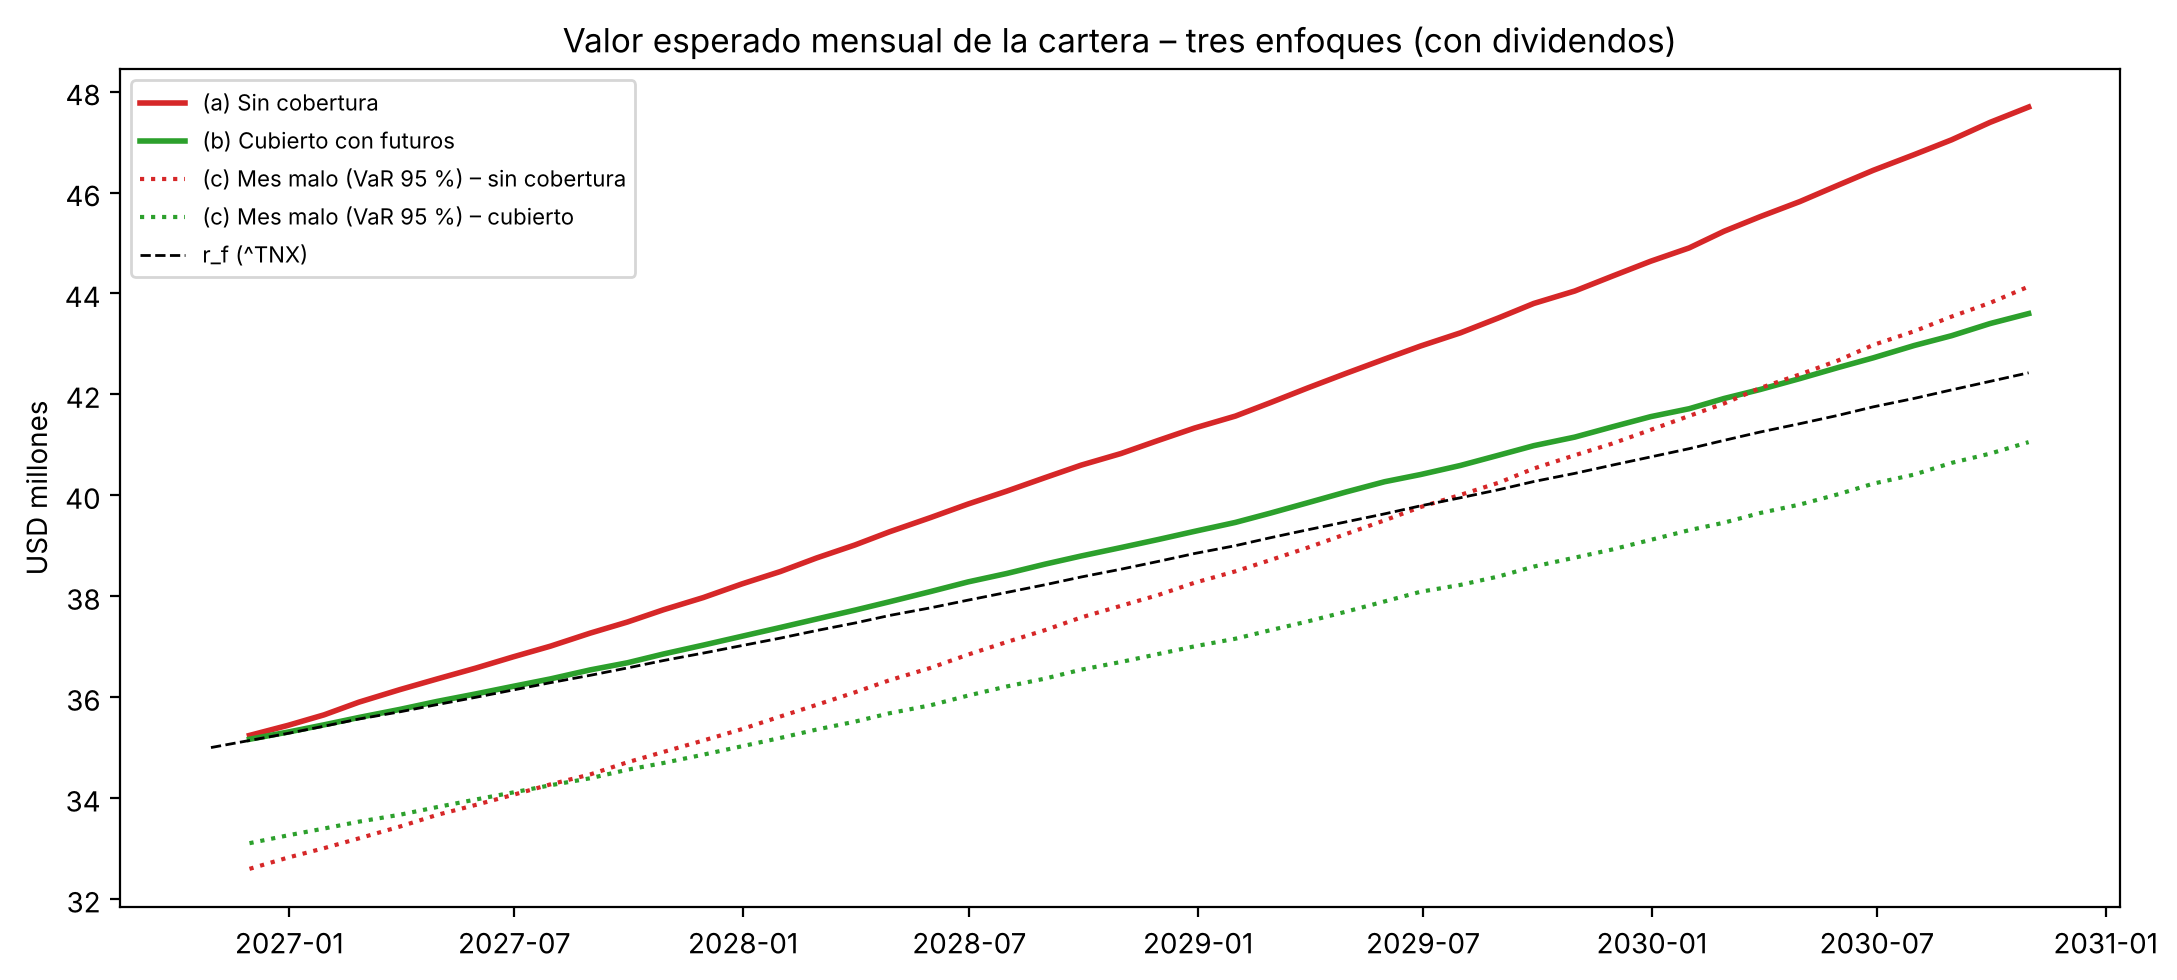

In [35]:
# 11.4 Gráfico: valor esperado mensual bajo los tres enfoques
fig, ax = plt.subplots(figsize=(11, 5))
x = pd.to_datetime(enf["Fecha"])
ax.plot(x, enf["(a) E[V]"] / 1e6, color="tab:red", lw=2, label="(a) Sin cobertura")
ax.plot(x, enf["(b) E[V]"] / 1e6, color="tab:green", lw=2, label="(b) Cubierto con futuros")
ax.plot(x, enf["(c) V si VaR 95 % sin"] / 1e6, color="tab:red", ls=":", label="(c) Mes malo (VaR 95 %) – sin cobertura")
ax.plot(x, enf["(c) V si VaR 95 % cub"] / 1e6, color="tab:green", ls=":", label="(c) Mes malo (VaR 95 %) – cubierto")
ax.plot(fechas, Vp * (1 + rf_mes) ** np.arange(n_mes + 1) / 1e6, "k--", lw=1, label="r_f (^TNX)")
ax.set_ylabel("USD millones"); ax.legend(fontsize=8, loc="upper left")
ax.set_title("Valor esperado mensual de la cartera – tres enfoques (con dividendos)")
plt.tight_layout(); fig.savefig(RAIZ / "outputs" / "figures" / "tres_enfoques_mensual_v2.png", dpi=150); plt.show()

Lectura del Punto 11:

- Dividendos: las tres pagan. CSCO rinde 1,60 % al año, ADI 1,03 % y AMGN 2,13 %. Como AMGN pesa 44 % en el GMV, el portafolio rinde 1,72 % anual en dividendos (0,142 % mensual), unos USD 50 mil el primer mes. En los 4 años se cobran cerca de USD 2,79 M sin cobertura y USD 2,66 M cubiertos. Con cobertura se cobra un poquito menos solo porque la cartera vale un poco menos en promedio, no porque se pierdan: el corto en futuros no toca los dividendos de nuestras acciones.
- (a) Sin cobertura: esperamos ganar 0,65 % al mes (0,50 % por precio y 0,14 % por dividendos), unos 8,0 % al año. A 4 años la cartera valdría USD 47,7 M, dividendos incluidos. Es el enfoque que más rinde, pero el más incierto (σ de USD 17,4 M, Punto 10).
- (b) Cubierto: esperamos ganar 0,46 % al mes (0,32 % por precio y 0,14 % por dividendos), unos 5,6 % al año, y USD 43,6 M a 4 años. Queda por encima de la tasa libre de riesgo (4,93 %). Los dividendos ayudan a eso: la cobertura nos quita la prima del mercado, pero los dividendos se siguen cobrando.
- (c) Ajustado por VaR: si el primer mes nos toca el mes malo del VaR 95 % (uno de cada 20 meses), sin cobertura perdemos USD 2,40 M y cubiertos USD 1,90 M. Al 99 % serían USD 3,53 M y 2,83 M. La cobertura le quita solo un 21 % a la pérdida del mes malo, porque dos terceras partes del riesgo mensual son propias de las acciones (R² = 0,33).
- Chequeo: el VaR 95 % del primer mes que sale de la simulación da 7,5 % sin cobertura y 6,2 % cubierto, un poco más que el del Punto 4 (6,9 % y 5,4 %). Es lógico: el Punto 4 usa la media histórica de la década (1,34 % mensual), y la simulación usa la expectativa de hoy (r_f + ERP), que es más baja. Igual, el orden de magnitud coincide.
- En resumen: sin cobertura ganamos más pero con más incertidumbre; cubiertos ganamos un poco más que la tasa libre de riesgo gracias a los dividendos; y aun cubiertos podemos perder unos USD 1,9 M en un mes malo por el comportamiento propio de CSCO, ADI y AMGN.

## Punto 12 – Sensibilidad a la beta: β = 0,6 y β = 1,5 (R14 – 6 %)

El enunciado pide suponer que la beta del portafolio fuera 0,6 o 1,5 en lugar de la nuestra (0,54). Para cada caso repetimos todo con la misma fórmula del Punto 6, el mismo contrato (NQZ6, F₀ = 28.534), los mismos márgenes, el mismo calendario de roll y las mismas 10.000 trayectorias (mismo índice y mismo riesgo propio, solo cambia la β):

$$N^* = \frac{\beta \cdot V_p}{F_0 \cdot Q_F} \qquad \text{Exposición sistemática} = \beta \cdot V_p \qquad \Delta V \approx \beta \cdot \Delta\text{índice} \cdot V_p$$

¿Qué dice la beta? Cuánto se mueve el portafolio cuando se mueve el índice. Con β = 1,5, si el Nasdaq-100 cae 10 %, el portafolio cae cerca de 15 %; con β = 0,6, cerca de 6 %. El futuro se mueve uno a uno con el índice, así que si el portafolio amplifica los movimientos se necesitan más contratos para compensarlos. Mantenemos el redondeo hacia abajo del Punto 6.

In [36]:
# 12.1 Contratos, exposición y sensibilidad para cada beta (escenario: índice −10 % en un mes)
casos = {"β = 0,6": 0.6, f"β = {beta_p:.4f} (nuestra)".replace(".", ","): beta_p, "β = 1,5": 1.5}
filas = []
for nombre, b in casos.items():
    n_opt = b * Vp / expo_contrato                          # N* = β·Vp / (F0·Q_F)
    n_ent = int(np.floor(n_opt))                            # hacia abajo (criterio del Punto 6)
    F1 = np.round(F0 * 0.90 / NQ["tick"]) * NQ["tick"]      # índice −10 %, precio al tick
    ticks = (F1 - F0) / NQ["tick"]
    pg = -ticks * NQ["valor_tick"] * n_ent                  # P&G del corto con ticks
    dV = b * (-0.10) * Vp                                   # cambio esperado del portafolio
    filas.append({"Caso": nombre, "β": b, "N*": n_opt, "N (contratos cortos)": n_ent, "Razón de cobertura": n_ent / n_opt,
                  "Exposición sistemática (USD)": b * Vp, "Exposición cubierta (USD)": n_ent * expo_contrato,
                  "VGI0 total (USD)": n_ent * VGI0_c, "VGM total (USD)": n_ent * VGM_c,
                  "Valor del tick para la posición (USD)": n_ent * NQ["valor_tick"],
                  "Índice −10 %: Δ portafolio (USD)": dV, "Índice −10 %: ticks": ticks,
                  "Índice −10 %: P&G corto (USD)": pg, "Índice −10 %: neto cubierto (USD)": dV + pg})
sens_b = pd.DataFrame(filas).set_index("Caso").T
sens_b.to_csv(PROC / "sensibilidad_beta_v2.csv")
sens_b.style.format(lambda x: f"{x:,.4f}" if abs(x) < 10 else f"{x:,.0f}")

Caso,"β = 0,6","β = 0,5401 (nuestra)","β = 1,5"
β,0.6000,0.5401,1.5000
N*,37,33,92
N (contratos cortos),36,33,91
Razón de cobertura,0.9783,0.9962,0.9892
Exposición sistemática (USD),"21,000,000","18,905,160","52,500,000"
Exposición cubierta (USD),"20,544,480","18,832,440","51,931,880"
VGI0 total (USD),"1,560,517","1,430,474","3,944,641"
VGM total (USD),"1,418,652","1,300,431","3,586,037"
Valor del tick para la posición (USD),180,165,455
Índice −10 %: Δ portafolio (USD),"-2,100,000","-1,890,516","-5,250,000"


In [37]:
# 12.2 Efecto sobre la cobertura en las 10.000 trayectorias (misma simulación del Punto 8)
def evaluar_beta(b, n_b):
    rp_b = rf_m + b * (r_mkt - rf_m) + sig_e * E                    # mismo mercado y mismo riesgo propio, otra β
    Vs = Vp * np.exp(np.cumsum(rp_b, axis=0)[-1])                   # valor final sin cobertura
    pg_b = pg_mes * (n_b / N)                                       # P&G del corto con n_b contratos
    Vc = Vs + pg_b.sum(axis=0) - costos_acum[-1] * n_b / N          # cubierto neto de costos
    VGI0_b, VGM_b = n_b * VGI0_c, n_b * VGM_c
    sal = np.full(n_sim, VGI0_b); mc = np.zeros(n_sim); nc = np.zeros(n_sim); rep = np.zeros(n_sim)
    for t in range(n_mes):
        sal = sal + mc + pg_b[t]; mc = np.where(sal < VGM_b, VGI0_b - sal, 0.0); nc += mc > 0; rep += mc
    q1 = S_arr[-1] <= np.quantile(S_arr[-1], .2)                    # quintil del mercado muy malo
    return {"E[V final] sin cobertura": Vs.mean(), "E[V final] cubierto": Vc.mean(),
            "E[rent. anual] sin cobertura": (Vs.mean() / Vp) ** .25 - 1, "E[rent. anual] cubierto": (Vc.mean() / Vp) ** .25 - 1,
            "σ sin cobertura": Vs.std(), "σ cubierto": Vc.std(), "Reducción de σ": 1 - Vc.std() / Vs.std(),
            "Mercado muy malo (Q1): E[V] sin cobertura": Vs[q1].mean(), "Mercado muy malo (Q1): E[V] cubierto": Vc[q1].mean(),
            "Llamados al margen (promedio)": nc.mean(), "Reposición total promedio (USD)": rep.mean(),
            "Reposición total P95 (USD)": np.quantile(rep, .95)}

sens_mc = pd.DataFrame({c_: evaluar_beta(sens_b.loc["β", c_], int(sens_b.loc["N (contratos cortos)", c_])) for c_ in sens_b.columns})
sens_mc.to_csv(PROC / "sensibilidad_beta_montecarlo_v2.csv")
sens_mc.style.format(lambda x: f"{x:,.0f}" if abs(x) > 100 else (f"{x:.2%}" if abs(x) < 1 else f"{x:,.2f}"))

,"β = 0,6","β = 0,5401 (nuestra)","β = 1,5"
E[V final] sin cobertura,"48,192,573","47,694,996","59,903,411"
E[V final] cubierto,"43,726,839","43,601,406","48,615,027"
E[rent. anual] sin cobertura,8.32%,8.04%,14.38%
E[rent. anual] cubierto,5.72%,5.65%,8.56%
σ sin cobertura,"18,326,687","17,445,249","42,097,810"
σ cubierto,"14,782,583","14,566,388","23,325,827"
Reducción de σ,19.34%,16.50%,44.59%
Mercado muy malo (Q1): E[V] sin cobertura,"34,206,864","35,069,763","23,793,045"
Mercado muy malo (Q1): E[V] cubierto,"41,548,664","41,799,746","42,351,483"
Llamados al margen (promedio),7.62,7.62,7.62


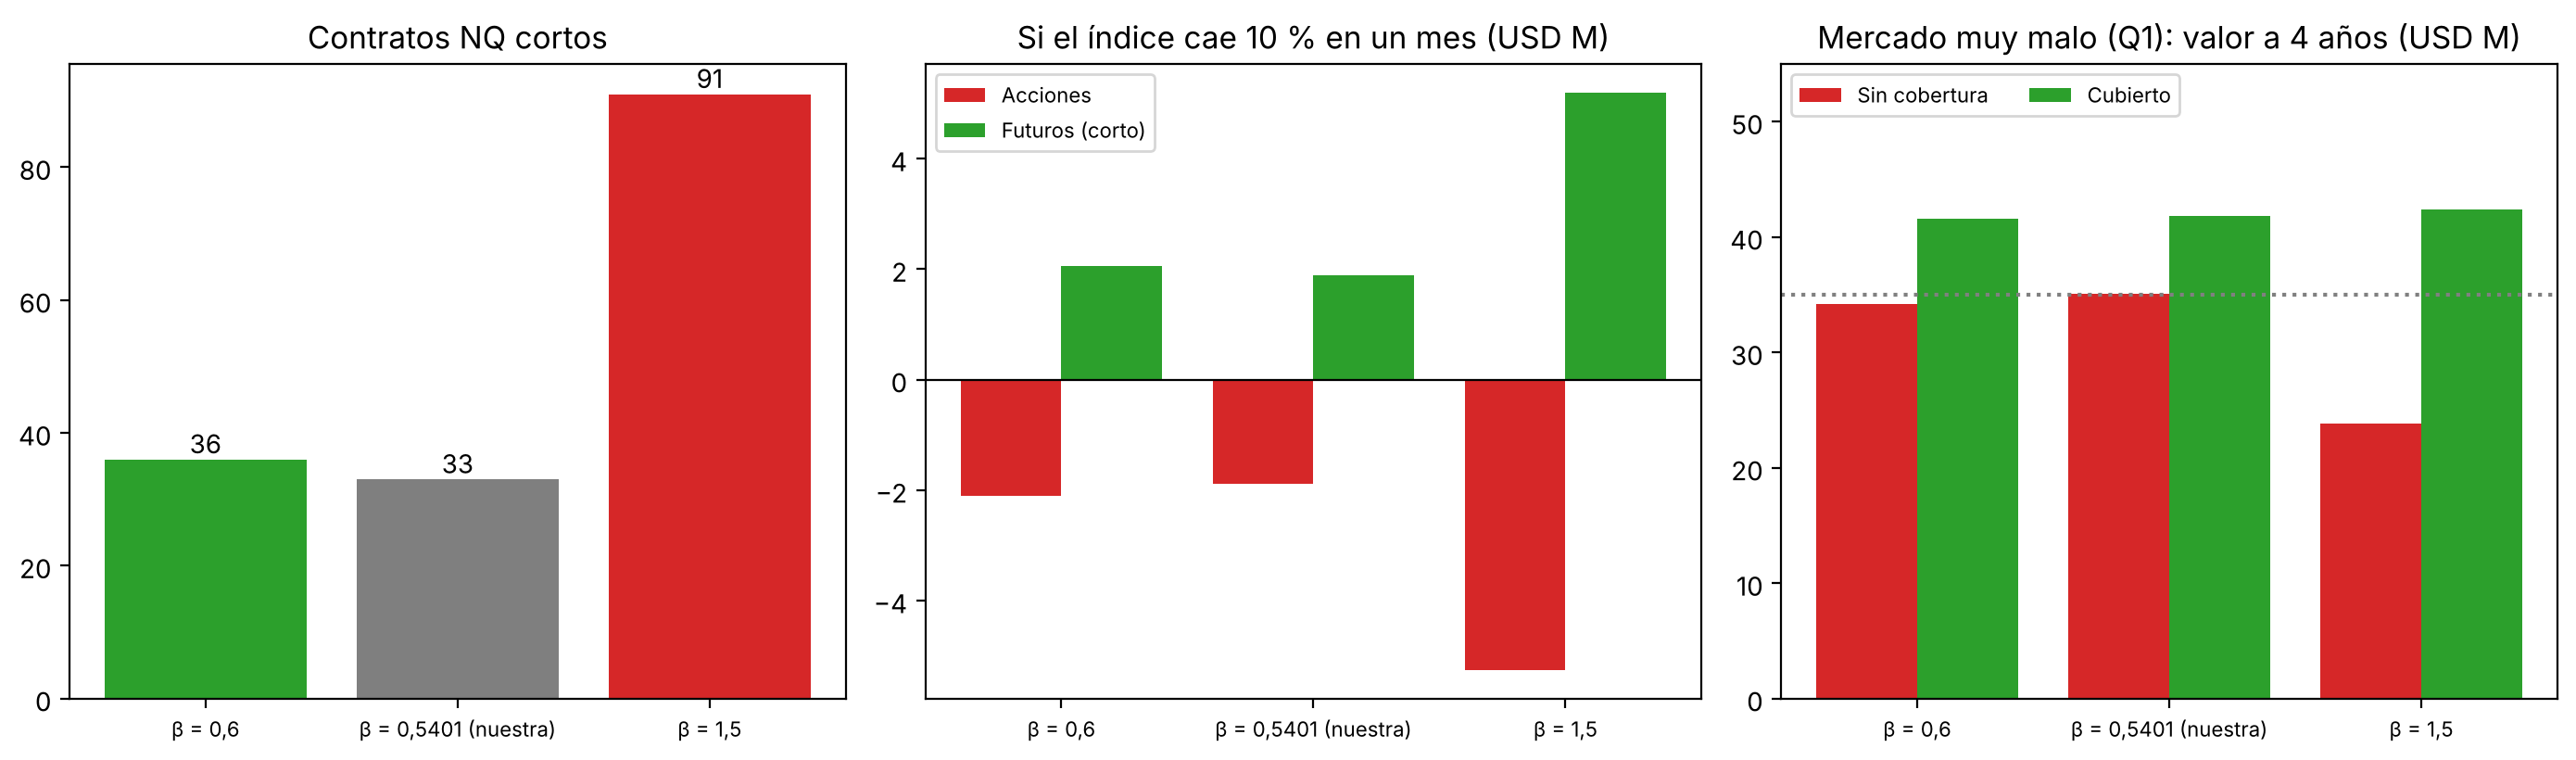

In [38]:
# 12.3 Gráfico: contratos, efecto de una caída del 10 % y protección en el mercado muy malo
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
cols = list(sens_b.columns); xx = np.arange(len(cols))
ax[0].bar(xx, sens_b.loc["N (contratos cortos)"], color=["tab:green", "tab:gray", "tab:red"])
for i, v in enumerate(sens_b.loc["N (contratos cortos)"]): ax[0].text(i, v, f"{int(v)}", ha="center", va="bottom")
ax[0].set_title("Contratos NQ cortos")
ax[1].bar(xx - .2, sens_b.loc["Índice −10 %: Δ portafolio (USD)"] / 1e6, width=.4, color="tab:red", label="Acciones")
ax[1].bar(xx + .2, sens_b.loc["Índice −10 %: P&G corto (USD)"] / 1e6, width=.4, color="tab:green", label="Futuros (corto)")
ax[1].axhline(0, color="black", lw=.8); ax[1].set_title("Si el índice cae 10 % en un mes (USD M)"); ax[1].legend(fontsize=8)
ax[2].bar(xx - .2, sens_mc.loc["Mercado muy malo (Q1): E[V] sin cobertura"] / 1e6, width=.4, color="tab:red", label="Sin cobertura")
ax[2].bar(xx + .2, sens_mc.loc["Mercado muy malo (Q1): E[V] cubierto"] / 1e6, width=.4, color="tab:green", label="Cubierto")
ax[2].axhline(Vp / 1e6, color="gray", ls=":"); ax[2].set_title("Mercado muy malo (Q1): valor a 4 años (USD M)")
ax[2].set_ylim(0, 55); ax[2].legend(fontsize=8, loc="upper left", ncol=2)
for a in ax: a.set_xticks(xx); a.set_xticklabels(cols, fontsize=8)
plt.tight_layout(); fig.savefig(RAIZ / "outputs" / "figures" / "sensibilidad_beta_v2.png", dpi=150); plt.show()

Lectura del Punto 12:

- Número de contratos: crece con la beta. Son 36 contratos con β = 0,6, 33 con la nuestra (0,54) y 91 con β = 1,5. Con β = 1,5 el N* da 91,997; con la regla del Punto 6 (hacia abajo) quedan 91 y la razón de cobertura es 98,9 %. Ojo que aquí 92 sobrecubriría apenas USD 2.600, así que también sería defensible redondear hacia arriba.
- Exposición sistemática: con β = 0,6 es USD 21 M; con β = 1,5 es USD 52,5 M, más que los USD 35 M invertidos. El portafolio se movería como si tuviéramos 1,5 veces su valor en el índice, y la cobertura tiene que ser de ese tamaño.
- Sensibilidad ante el índice (cae 10 % en un mes): sin cobertura se pierden USD 2,10 M con β = 0,6 y USD 5,25 M con β = 1,5. En los tres casos el corto compensa casi todo (−11.414 ticks) y lo que queda, entre USD 7 mil y 57 mil, sale del redondeo de contratos. Cada tick pesa más con β alta: USD 180 por tick con β = 0,6 y USD 455 con β = 1,5.
- ¿Por qué una beta mayor exige una cobertura más intensa? Cada contrato compensa el movimiento del índice uno a uno. Si el portafolio amplifica las caídas del mercado (β > 1), hacen falta más contratos para igualar la pérdida. Con β = 1,5 se necesitan 2,5 veces los contratos del caso β = 0,6. Eso significa más garantía inicial (USD 3,94 M frente a USD 1,56 M) y mucha más caja para el margen: USD 25,0 M de reposición promedio en 4 años frente a USD 9,9 M (P95 de USD 72 M frente a 28,5 M). El número de llamados es el mismo en promedio (7,6), porque las pérdidas y los márgenes crecen en la misma proporción; lo que cambia es cuánta plata hay que poner.
- Efecto sobre la cobertura: con β = 1,5 la cobertura sirve mucho más. Reduce la dispersión del valor final un 45 %, contra 17–19 % con β baja. En el mercado muy malo (Q1), sin cobertura el portafolio terminaría en USD 23,8 M y cubierto en USD 42,4 M. Con β alta casi todo el riesgo es de mercado, y ese es justo el que el futuro sabe quitar. Con β baja, como la nuestra, la mayor parte del riesgo es propio de las acciones y el futuro ayuda menos.
- Un detalle: con β = 1,5 el cubierto todavía rinde 8,6 % anual esperado. Con N fijo, cuando el mercado sube el portafolio crece más rápido que la cobertura y queda algo de exposición; si se recalcularan los contratos en cada roll quedaría más cerca de la tasa libre de riesgo.

## Conclusión general

- Nuestro portafolio: GMV con CSCO 36,71 %, ADI 19,37 % y AMGN 43,92 % (USD 35 M). Volatilidad de 17,8 % anual y beta mensual de 0,54 frente al Nasdaq-100. Solo un 33 % de su riesgo es de mercado (R² = 0,33), porque AMGN casi no se mueve con el índice.
- La cobertura: 33 contratos cortos E-mini Nasdaq-100 (NQ) en CME, renovados cada trimestre siguiendo los vencimientos de CME (17 contratos, 16 rolls). Cubre el 99,6 % de la exposición sistemática y pide USD 1,43 M de garantía inicial.
- Qué esperamos en 4 años (10.000 trayectorias, μ = r_f + ERP, dividendos incluidos):

| | Sin cobertura | Cubierto |
|---|---|---|
| Valor esperado | USD 47,7 M | USD 43,6 M |
| Rentabilidad esperada anual | 8,0 % | 5,6 % (r_f = 4,93 %) |
| Dispersión del valor final (σ) | USD 17,4 M | USD 14,6 M |
| Si al mercado le va muy mal (Q1, −22 %) | USD 35,1 M | USD 41,8 M |
| Pérdida en un mes malo (VaR 95 %) | USD 2,40 M | USD 1,90 M |
| Caja para llamados al margen (prom. / P95) | — | USD 9,1 M / 26,2 M |

- Recomendación al gerente:
    - La cobertura hace bien lo que promete: si el mercado se cae, el portafolio cubierto termina cerca de USD 40–42 M en vez de perder plata. El precio es renunciar a la prima del mercado, unos USD 4,1 M en valor esperado (−USD 3,7 M en valor presente).
    - No convierte este portafolio en un bono. Con β = 0,54 y R² = 0,33, dos terceras partes del riesgo son propias de CSCO, ADI y AMGN, y eso un futuro sobre el índice no lo quita. La dispersión total baja solo 17 %.
    - Tiene sentido si para la entidad lo más importante es protegerse de una caída fuerte del mercado. Si se aplica, hay que tener caja disponible para los llamados al margen, que llegan justo cuando el mercado sube.
    - Para un portafolio con más beta (Punto 12) la cobertura sería más útil, pero también más exigente en caja. Una mejora a evaluar es recalcular los contratos en cada roll.